# Credit Default Risk Analysis: Project Pipeline

**Dataset:** Give Me Some Credit (`datasets/cs-training.csv`)  
**Target Variable:** `SeriousDlqin2yrs` (`1` = experienced 90 days past due or worse delinquency within 2 years; `0` = otherwise)

### Project Pipeline Overview
0. **Problem Framing:** Define the underwriting decision, approval-rate / bad-rate targets, evaluation metrics, and dataset assumptions.
1. **Setup & Load:** Importing libraries and optional libraries, setting up workspace saving by pickling (`save_workspace_variables`), and load `cs-training.csv`.
2. **Data Audit:** Inspect schema, missingness, duplicate records, class imbalance, and suspect values 
3. **Clean Data:** Apply idempotent, re-runnable cleaning on a copy of the raw original DataFrame, consolidate special delinquency codes into a single indicator, flag missing income once, and document row impacts.
4. **Exploratory Data Analysis (EDA):** Examine univariate distributions, boxplots by default status, empirical default rates across risk buckets, and training-set feature correlations.
5. **Feature Engineering & Subset Selection:** Apply `np.log1p` transforms to preserve zero-inflation signals, engineer household purchasing power (`LogIncome2Members`), and select a non-collinear 12-feature subset (`SELECTED_FEATURES`).
6. **Model Training:** Fit and tune baseline and advanced models (Logistic Regression, Ridge, Lasso, Elastic Net, Gradient Boosting, subsampled RBF SVM, and EBM) using Stratified Cross-Validation (5-fold for the logistic models and GBM; 3-fold for the EBM and the SVM subsample).
7. **Evaluation & Calibration:** Compare holdout test ROC-AUC, PR-AUC, Brier scores, calibration curves, feature importances, and confusion matrices.
8. **Financial / Business Impact:** Define a loan-level cost/profit matrix, sweep probability cutoffs to maximize expected net profit, and compare against an approve-all baseline.
9. **Conclusions & Next Steps:** Summarize key delinquency drivers, recommended underwriting cutoffs, dataset limitations, and production next steps.

## 0. Problem Framing
- **Question:** Which borrower characteristics predict serious delinquency (`SeriousDlqin2yrs = 1`), and how accurately can we estimate calibrated default probabilities (PDs) to rank applicants by credit risk?
- **Stakeholder / decision:** Consumer credit underwriting team setting automated probability-of-default cutoffs to maximize expected portfolio profit while keeping the bad rate among approved borrowers below a target ceiling (~2.5-3.0% vs. the 6.68% raw base rate; 6.73% after cleaning).
- **Success metric:** Out-of-fold 5-fold Stratified Cross-Validation **ROC-AUC** for primary model selection and **PR-AUC (Average Precision)** to evaluate minority-class ranking (~6.68% positives), paired with **Brier score** and **reliability curves** in Section 7 to verify that predicted probabilities are usable as true PDs.
- **Assumptions / limits:** Cross-sectional observational snapshot with no origination timestamps or macroeconomic covariates; anonymized borrower records; subject to selection bias because outcomes are observed only for historically approved applicants (no reject inference).

## 1. Setup & Load
- **Dataset download:** `kaggle competitions download -c GiveMeSomeCredit` (requires a Kaggle API token and accepting competition rules).
- **Dependencies:** Core pipeline uses `pandas`, `numpy`, `scikit-learn`, `matplotlib`, `seaborn`, and `tqdm`. Optional cells in Section 6 use `interpret` for `ExplainableBoostingClassifier`.

In [1]:
import pickle
import types
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from tqdm.auto import tqdm

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
    average_precision_score,
    brier_score_loss,
    confusion_matrix,
    classification_report
)

_PICKLE_DIR = Path("pickles")
_SKIP = {
    "In", "Out", "exit", "quit", "get_ipython", "open",
    "save_workspace_variables", "load_workspace_variables"
}

def save_workspace_variables(names=None):
    """Pickle specified variables (or all globals if names=None) at key pipeline checkpoints."""
    _PICKLE_DIR.mkdir(exist_ok=True)
    target_names = names if names is not None else list(globals().keys())
    for name in target_names:
        if name.startswith("_") or name in _SKIP or name not in globals():
            continue
        value = globals()[name]
        if isinstance(value, (types.ModuleType, types.FunctionType, types.BuiltinFunctionType, type)):
            continue
        try:
            data = pickle.dumps(value)  # serialize first so a failure never leaves a broken .pkl
        except Exception as e:
            print(f"skipped {name}: {e}")
            continue
        (_PICKLE_DIR / f"{name}.pkl").write_bytes(data)

def load_workspace_variables():
    """Restore saved variables into this notebook's globals."""
    if not _PICKLE_DIR.exists():
        raise FileNotFoundError("The pickles folder does not exist. Run the preceding cells first.")
    for path in sorted(_PICKLE_DIR.glob("*.pkl")):
        if path.stat().st_size == 0:
            print(f"skipped empty pickle: {path.name}")
            continue
        with path.open("rb") as file:
            globals()[path.stem] = pickle.load(file)

SEED = 42
TARGET = "SeriousDlqin2yrs"
csv_path = Path("datasets/cs-training.csv") if Path("datasets/cs-training.csv").exists() else Path("cs-training.csv")
df_raw = pd.read_csv(csv_path, index_col=0)
df = df_raw.copy()
print(f"Loaded dataset shape: {df.shape}")

save_workspace_variables(["SEED", "TARGET", "df_raw", "df"])

Loaded dataset shape: (150000, 11)


## 2. Data Audit

In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: fl

In [3]:
missing_audit = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean().mul(100)
})
missing_audit

,missing_count,missing_percent
SeriousDlqin2yrs,0,0.000000
RevolvingUtilizationOfUnsecuredLines,0,0.000000
age,0,0.000000
NumberOfTime30-59DaysPastDueNotWorse,0,0.000000
DebtRatio,0,0.000000
MonthlyIncome,29731,19.820667
NumberOfOpenCreditLinesAndLoans,0,0.000000
NumberOfTimes90DaysLate,0,0.000000
NumberRealEstateLoansOrLines,0,0.000000
NumberOfTime60-89DaysPastDueNotWorse,0,0.000000


In [4]:
duplicate_audit = pd.DataFrame({
    "duplicate_count": [df.duplicated().sum()],
    "duplicate_percent": [df.duplicated().mean() * 100],
    "total_rows": [len(df)]
})
duplicate_audit

,duplicate_count,duplicate_percent,total_rows
0,609,0.406,150000


In [5]:
target_dist = df[TARGET].value_counts(normalize=True)
print(target_dist)

SeriousDlqin2yrs
0    0.93316
1    0.06684
Name: proportion, dtype: float64


In [6]:
ranges = pd.DataFrame({
    "min": df.min(),
    "max": df.max()
})
print(ranges)

                                      min        max
SeriousDlqin2yrs                      0.0        1.0
RevolvingUtilizationOfUnsecuredLines  0.0    50708.0
age                                   0.0      109.0
NumberOfTime30-59DaysPastDueNotWorse  0.0       98.0
DebtRatio                             0.0   329664.0
MonthlyIncome                         0.0  3008750.0
NumberOfOpenCreditLinesAndLoans       0.0       58.0
NumberOfTimes90DaysLate               0.0       98.0
NumberRealEstateLoansOrLines          0.0       54.0
NumberOfTime60-89DaysPastDueNotWorse  0.0       98.0
NumberOfDependents                    0.0       20.0


In [7]:
df["DebtRatio"].sort_values(ascending=False)

60153     329664.0
36601     326442.0
127048    307001.0
58901     220516.0
4855      168835.0
            ...   
31896          0.0
122001         0.0
6805           0.0
68157          0.0
90072          0.0
Name: DebtRatio, Length: 150000, dtype: float64

In [8]:
df["NumberOfTime60-89DaysPastDueNotWorse"].sort_values(ascending=False)

29564     98
19180     98
84806     98
149440    98
149240    98
          ..
12         0
13         0
4019       0
15         0
16         0
Name: NumberOfTime60-89DaysPastDueNotWorse, Length: 150000, dtype: int64

In [9]:
df["age"].value_counts()

age
49     3837
48     3806
50     3753
47     3719
63     3719
       ... 
102       3
109       2
107       1
105       1
0         1
Name: count, Length: 86, dtype: int64

In [10]:
# Verify the counts quoted in the cleaning log (run on the raw frame, before masking)
print(f"Zero MonthlyIncome rows: {(df['MonthlyIncome'] == 0).sum():,}")
print(f"DebtRatio > 5 rows: {(df['DebtRatio'] > 5).sum():,}")
print(f"age == 0 rows: {(df['age'] == 0).sum():,}")


Zero MonthlyIncome rows: 1,634
DebtRatio > 5 rows: 29,646
age == 0 rows: 1


We see several suspect values: `age = 0`, past-due event counts of `96` or `98`, and extreme `DebtRatio` values (> 5). We will convert these invalid entries to `NaN` so they can be properly handled downstream without distorting linear or tree splits.

In [11]:
base_default_rate = df[TARGET].mean() * 100
print(f"Base default rate = {base_default_rate:.2f}%")

Base default rate = 6.68%


In [12]:
past_due_columns = [
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate"
]
special_code_rates = {}
for column in past_due_columns:
    code_mask = df_raw[column].isin([96, 98])
    special_code_rates[column] = df_raw.loc[code_mask, TARGET].agg(["mean", "count"])
    special_code_rates[column]["default_rate_percent"] = (
        special_code_rates[column]["mean"] * 100
    )

special_code_default_rates = pd.DataFrame(special_code_rates).T
special_code_default_rates

,mean,count,default_rate_percent
NumberOfTime30-59DaysPastDueNotWorse,0.546468,269.0,54.64684
NumberOfTime60-89DaysPastDueNotWorse,0.546468,269.0,54.64684
NumberOfTimes90DaysLate,0.546468,269.0,54.64684


Notice that rows with special codes (`96`, `98`) have a very high default rate ($\approx 54.65\%$), far above the base default rate ($\approx 6.68\%$). Moreover, all three delinquency columns have the exact same 269 rows with codes `96`/`98` (perfect collinearity). So, we'll just create **one** consolidated indicator variable (`PastDue_SpecialCode`) before replacing `96` and `98` with `NaN`.

## 3. Cleaning
### Step 1: Fill suspect values with NaN (idempotent / re-runnable)

In [13]:
# Reset df from df_raw so rerunning this cell never overwrites PastDue_SpecialCode with zeros.
df = df_raw.copy()

# Consolidate the identical 96/98 sentinel flags into a single binary indicator.
df["PastDue_SpecialCode"] = df[past_due_columns].isin([96, 98]).any(axis=1).astype(int)
for column in past_due_columns:
    df.loc[df[column].isin([96, 98]), column] = np.nan

# Values of DebtRatio > 5 (typically caused by missing/zero income denominators) are set to NaN.
df.loc[df["DebtRatio"] > 5, "DebtRatio"] = np.nan
df.loc[df["age"] == 0, "age"] = np.nan
df.loc[df["MonthlyIncome"] == 0, "MonthlyIncome"] = np.nan

save_workspace_variables(["df", "past_due_columns", "base_default_rate", "special_code_default_rates"])

### Cleaning Decision Log
Log every decision and its row impact. `df_raw` is kept untouched so cleaning is completely reproducible.

| Issue | Decision | Rationale |
|---|---|---|
| Duplicate records | Drop `1,633` duplicate rows (`Credit_df.drop_duplicates()`) | Prevents identical borrower profiles from leaking across train/test splits and over-weighting repeated observations. Only `609` rows are exact duplicates in the raw file; the other ~1,024 become identical *after* sentinel/outlier masking, so this step also collapses some borrowers who differ only in values later blanked out (deduplicating before masking is the stricter alternative). |
| Missing or zero `MonthlyIncome` (`29,731` missing + `1,634` zeros) | Convert `0` to `NaN`, create `IncomeMissing` binary flag once, and median-impute inside the CV `Pipeline` | Zero monthly income is a reporting artifact, so we will flag the missingness to preserve the signal while in-pipeline imputation prevents test-set leakage. |
| Missing `NumberOfDependents` (`3,924` rows, ~2.6%) | Keep as `NaN` in `Credit_df`; impute median inside the CV `Pipeline` | Low missingness rate; deferring imputation to the modeling pipeline avoids leakage. |
| `age = 0` (`1` row) | Convert `0` to `NaN` and drop row (`dropna(subset=['age'])`) | A 0-year-old borrower is an invalid record; dropping 1 row out of 150,000 has zero statistical cost. |
| Past-due codes `96`, `98` (`269` rows) | Create a single `PastDue_SpecialCode` flag (`1` if `96` or `98`, `0` otherwise), then replace `96`/`98` with `NaN` | Preserves the ~54.65% default signal without distorting numeric delinquency counts or introducing 3 identical collinear flags. |
| Extreme `DebtRatio > 5` (`29,623` rows) & `RevolvingUtilization` outliers | Replace `DebtRatio > 5` with `NaN`; apply `np.log1p` transform and cap `RevolvingUtilization` at the 99th training percentile | Eliminates unscaled dollar-debt artifacts when income is missing and bounds extreme right-tail leverage without corrupting zero values. |

In [14]:

Credit_df = df.copy()
duplicate_count = Credit_df.duplicated().sum()
Credit_df = Credit_df.drop_duplicates().copy()
print(f"Dropped {duplicate_count:,} duplicate rows.")

# Create IncomeMissing once here; learned imputations happen inside the pipeline after train/test split.
Credit_df["IncomeMissing"] = Credit_df["MonthlyIncome"].isna().astype(int)
Credit_df = Credit_df.dropna(subset=["age"]).copy()
print(f"Cleaned Credit_df shape: {Credit_df.shape}")

save_workspace_variables(["Credit_df", "duplicate_count"])

Dropped 1,633 duplicate rows.
Cleaned Credit_df shape: (148366, 13)


## 4. Exploratory Data Analysis

### Histograms

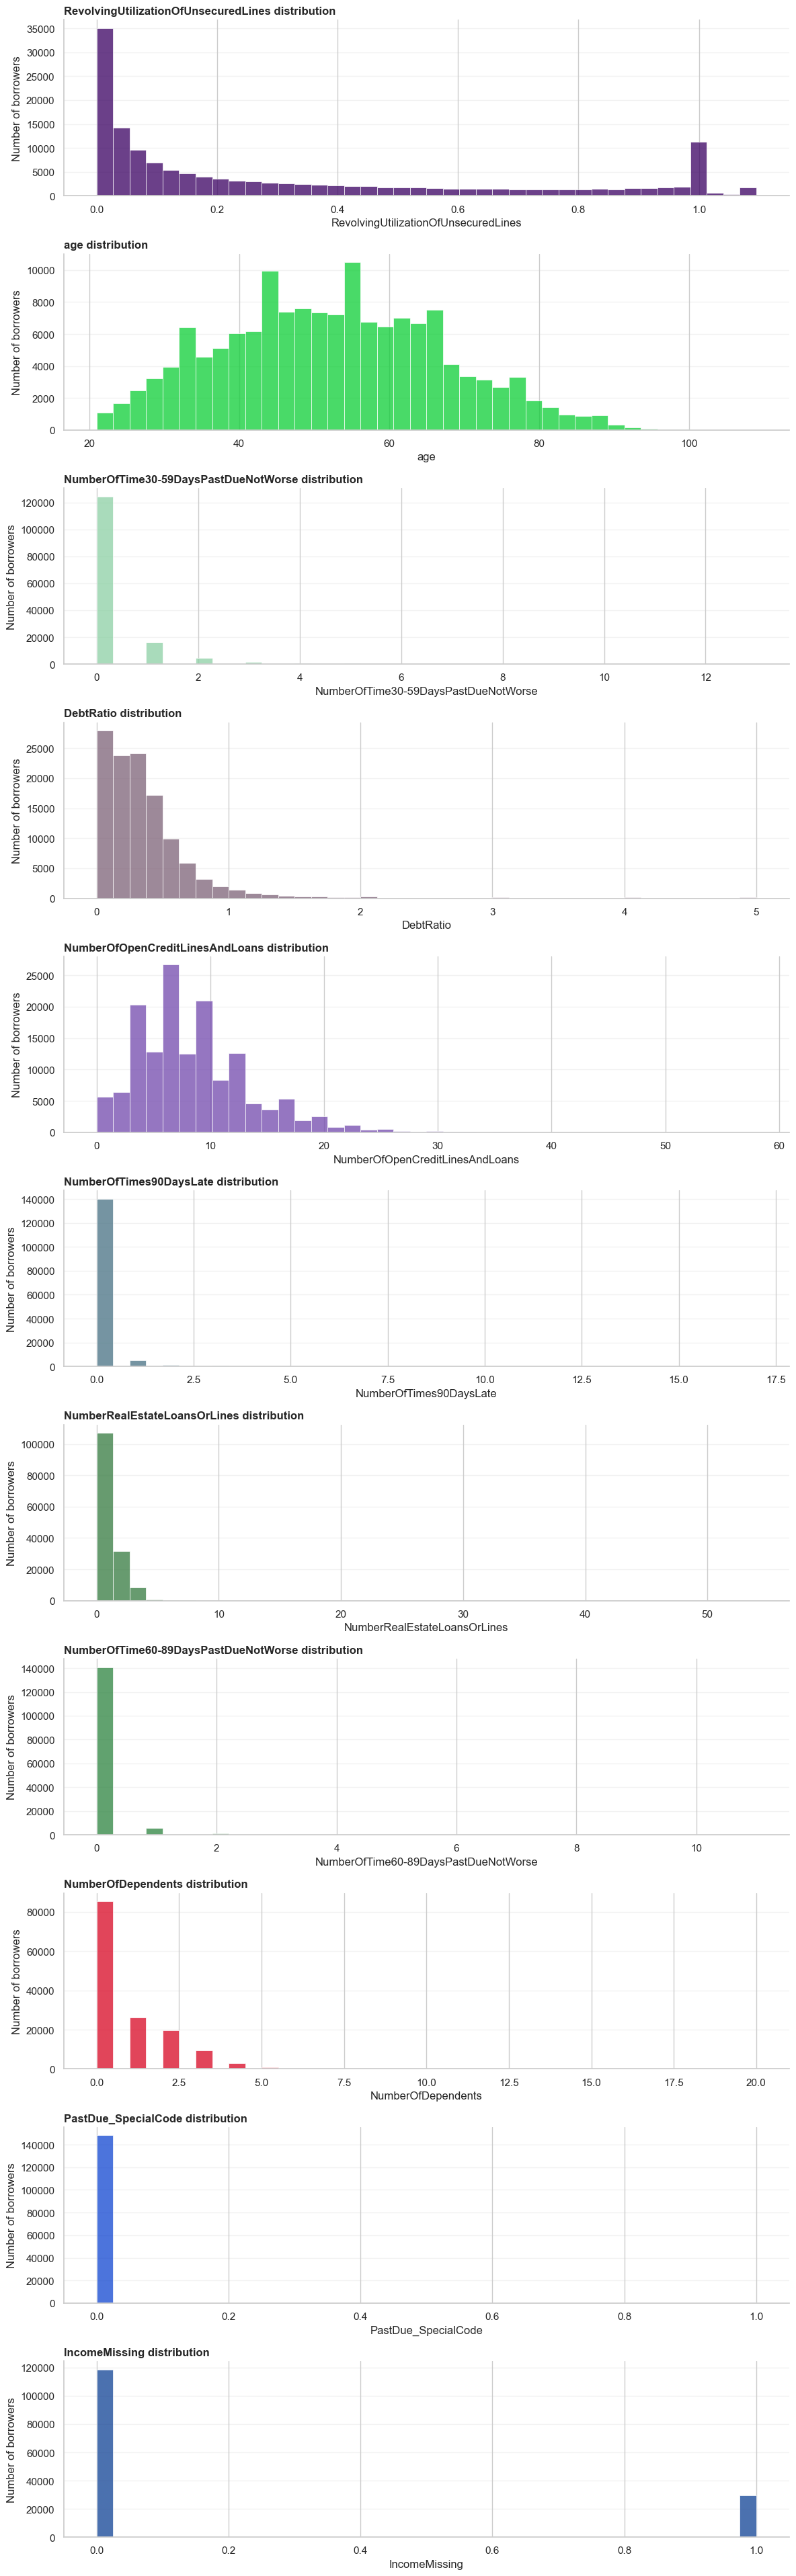

In [15]:
_color_rng = random.Random(SEED)
def random_hex_color():
    return f"#{_color_rng.randint(0, 0xFFFFFF):06x}"

features = [col for col in Credit_df.columns.drop("MonthlyIncome") if col != TARGET]
sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(len(features), 1, figsize=(12, 3.5 * len(features)))
if len(features) == 1:
    axes = [axes]
for ax, feature in zip(axes, features):
    values = Credit_df[feature].dropna()
    if feature == "RevolvingUtilizationOfUnsecuredLines":
        # Plot the central 99% so denominator artifacts do not compress the histogram.
        values = values.clip(upper=values.quantile(0.99))
    sns.histplot(values, bins=40, color= random_hex_color(), edgecolor="white", linewidth=0.5, ax=ax)
    ax.set_title(f"{feature} distribution", loc="left", fontweight="bold")
    ax.set_xlabel(feature)
    ax.set_ylabel("Number of borrowers")
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

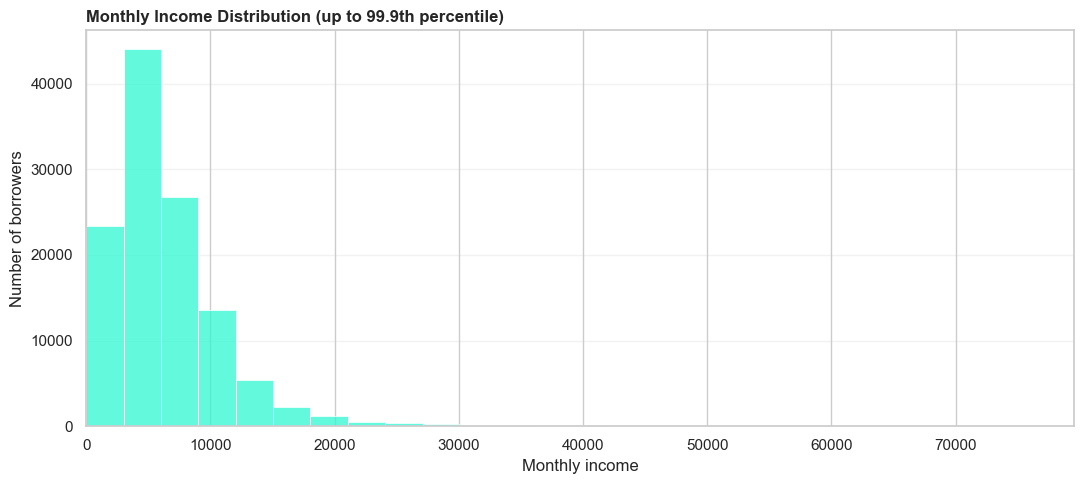

In [16]:
income_for_plot = Credit_df["MonthlyIncome"].dropna()
plt.figure(figsize=(11, 5))
sns.histplot(income_for_plot, bins=1000, color=random_hex_color(), edgecolor="white", linewidth=0.5)
plt.xlim(0, income_for_plot.quantile(0.999))
plt.title("Monthly Income Distribution (up to 99.9th percentile)", loc="left", fontweight="bold")
plt.xlabel("Monthly income")
plt.ylabel("Number of borrowers")
plt.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

As we can see, `MonthlyIncome` exhibits extreme right skew; clipping the plot axis at the 99.9th percentile is required to visualize the bulk of borrowers.

### Boxplots

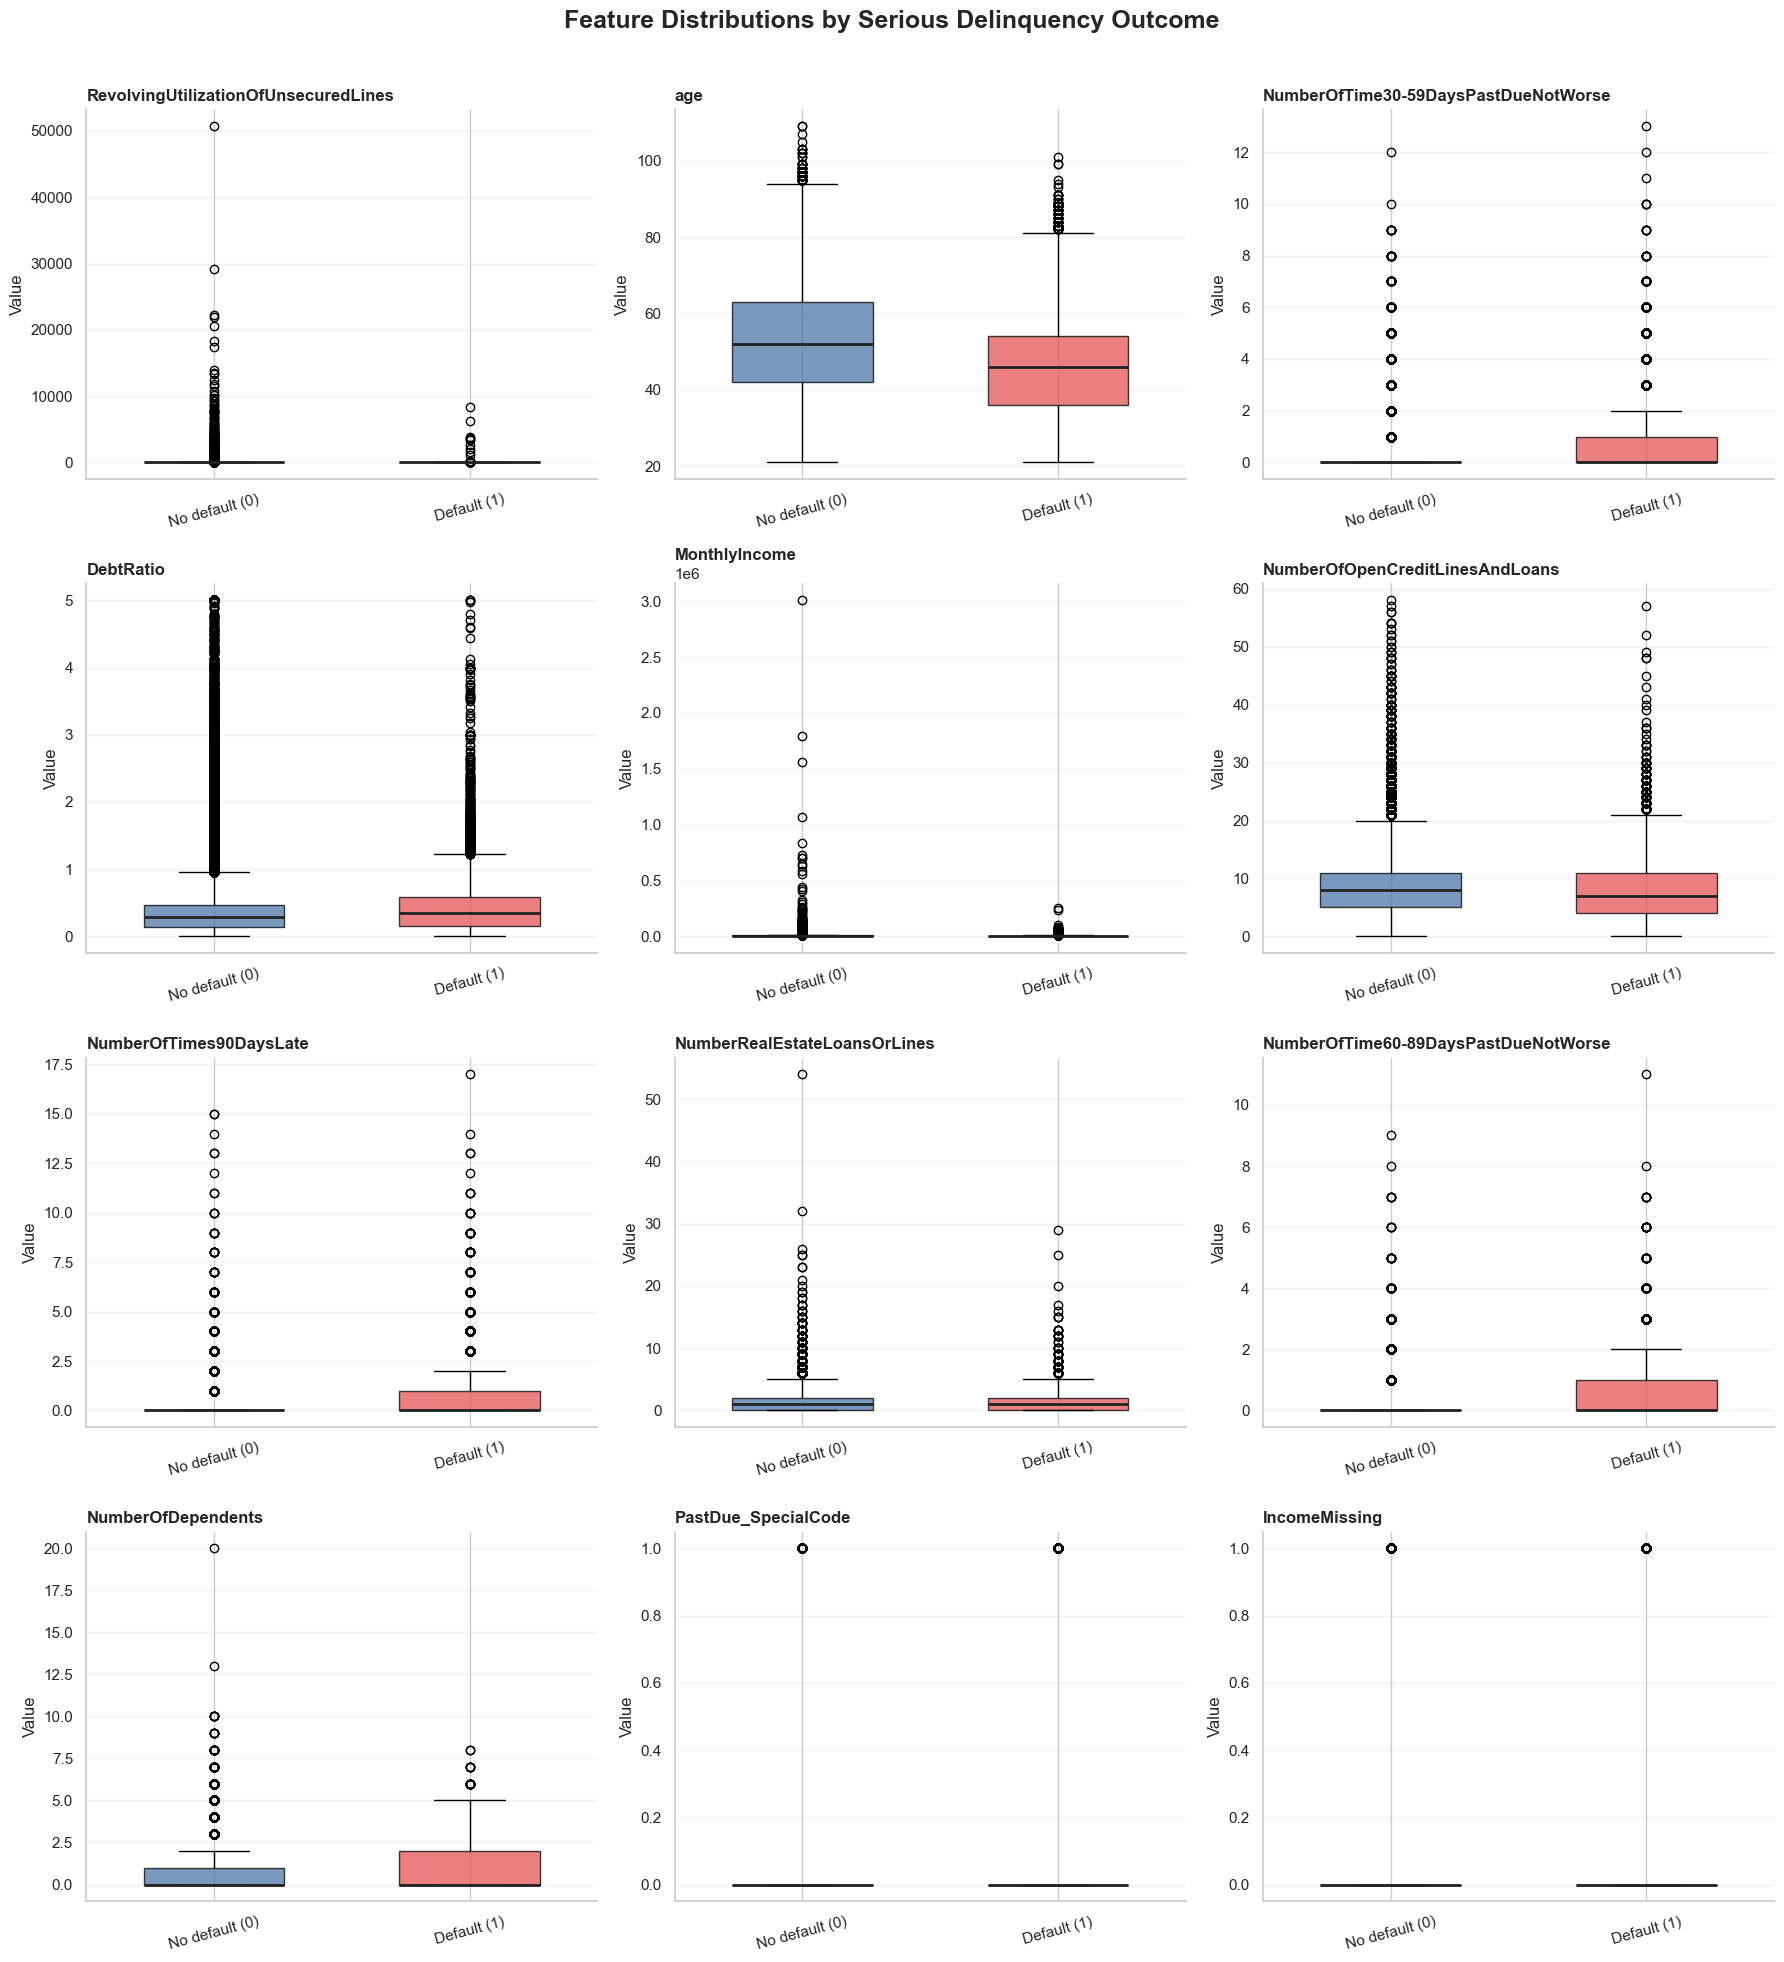

In [17]:
# Box plots for every feature, split by response value.
boxplot_features = [col for col in Credit_df.columns if col != TARGET]
boxplot_columns = 3
boxplot_rows = int(np.ceil(len(boxplot_features) / boxplot_columns))

fig, axes = plt.subplots(
    boxplot_rows,
    boxplot_columns,
    figsize=(18, 5 * boxplot_rows),
    squeeze=False
)
fig.suptitle("Feature Distributions by Serious Delinquency Outcome", fontsize=18, fontweight="bold")

for ax, feature in zip(axes.flat, boxplot_features):
    values_by_response = [
        Credit_df.loc[Credit_df[TARGET] == response, feature].dropna()
        for response in [0, 1]
    ]
    box = ax.boxplot(
        values_by_response,
        tick_labels=["No default (0)", "Default (1)"],
        patch_artist=True,
        showfliers=True,
        widths=0.55
    )
    for patch, color in zip(box["boxes"], ["#4C78A8", "#E45756"]):
        patch.set_facecolor(color)
        patch.set_alpha(0.75)
    for median in box["medians"]:
        median.set_color("#222222")
        median.set_linewidth(2)
    ax.set_title(feature, loc="left", fontweight="bold")
    ax.set_ylabel("Value")
    ax.tick_params(axis="x", rotation=15)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)

for ax in axes.flat[len(boxplot_features):]:
    ax.set_visible(False)

plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.show()

Borrowers who default (`SeriousDlqin2yrs = 1`) tend to be younger, have lower median monthly income with a narrower IQR, and exhibit substantially higher revolving utilization and debt ratios.

## Default Rate by Risk Bucket
$$\text{Default Rate} = \dfrac{\text{Number of borrowers who default}}{\text{Total number of borrowers}}$$

In [18]:
age_bins = [0, 30, 40, 50, 60, 70, np.inf]
age_labels = ["Under 30", "30-39", "40-49", "50-59", "60-69", "70+"]

age_default_rate = (
    Credit_df.assign(
        age_group=pd.cut(
            Credit_df["age"],
            bins=age_bins,
            labels=age_labels
        )
    )
    .groupby("age_group", observed=False)[TARGET]
    .agg(["mean", "count"])
    .rename(columns={"mean": "default_rate"})
)

age_default_rate["default_rate_percent"] = (
    age_default_rate["default_rate"] * 100
)

age_default_rate

,default_rate,count,default_rate_percent
age_group,,,
Under 30,0.117772,10376,11.777178
30-39,0.098532,24175,9.853154
40-49,0.082953,34815,8.295275
50-59,0.062131,34524,6.213069
60-69,0.035150,27084,3.514990
70+,0.022884,17392,2.288408


For EDA bucket visualization, we also inspect `TotalPastDueEvents = (30-59 days) + (60-89 days) + (90+ days)` alongside the individual delinquency windows (we will exclude `TotalPastDueEvents` from the final modeling subset to avoid exact linear collinearity).

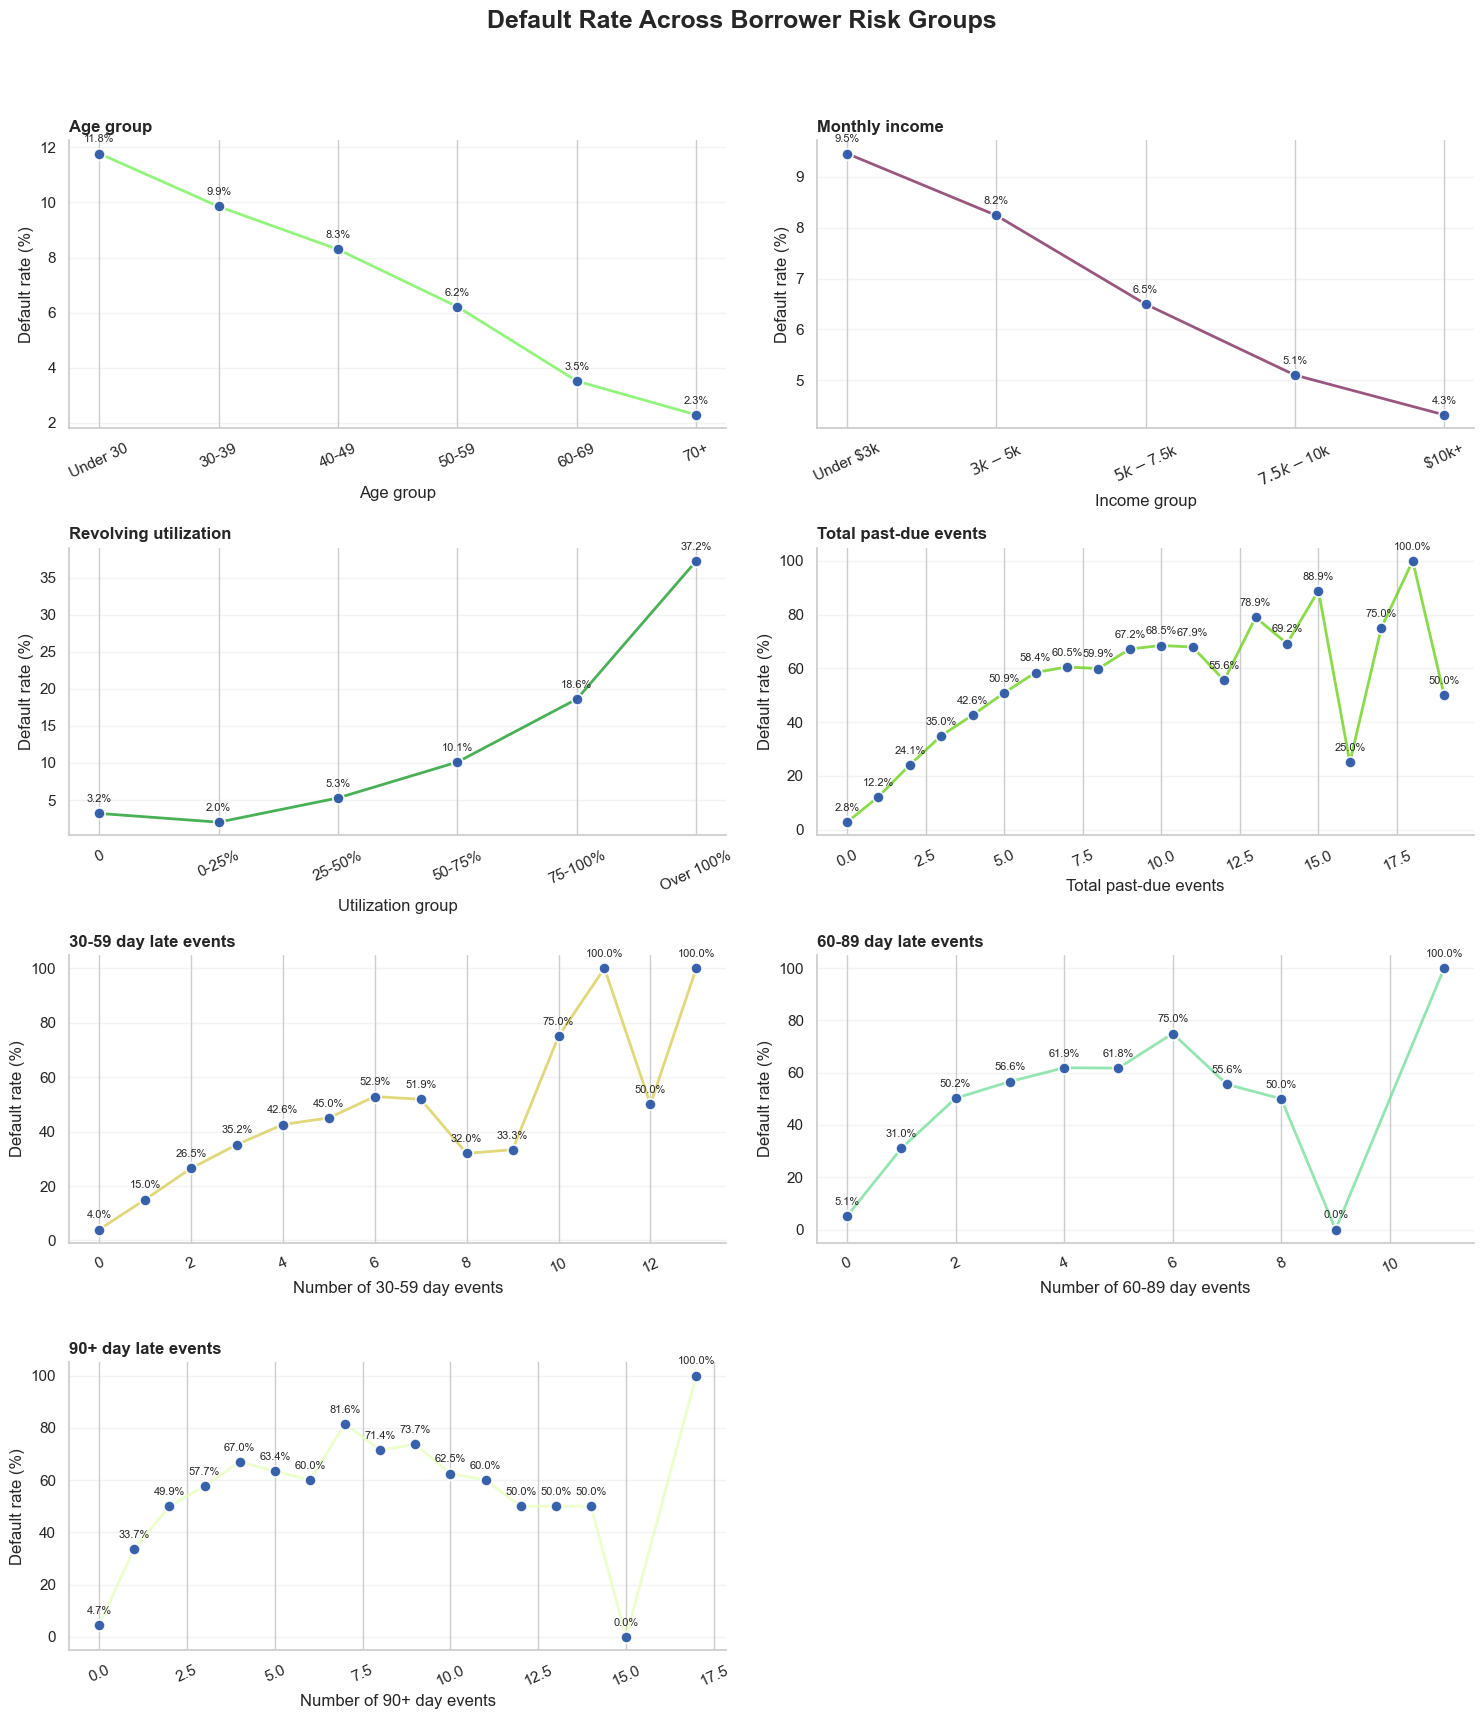

In [19]:
def default_rate_by_group(data, group_column, bins, labels):
    grouped = (
        data.assign(group=pd.cut(data[group_column], bins=bins, labels=labels))
        .groupby("group", observed=False)[TARGET]
        .agg(["mean", "count"])
    )
    grouped["default_rate_percent"] = grouped["mean"] * 100
    return grouped

income_bins = [-np.inf, 3000, 5000, 7500, 10000, np.inf]
income_labels = ["Under $3k", "$3k-$5k", "$5k-$7.5k", "$7.5k-$10k", "$10k+"]
income_default_rate = default_rate_by_group(Credit_df, "MonthlyIncome", income_bins, income_labels)

utilization_bins = [-np.inf, 0, 0.25, 0.5, 0.75, 1, np.inf]
utilization_labels = ["0", "0-25%", "25-50%", "50-75%", "75-100%", "Over 100%"]
utilization_default_rate = default_rate_by_group(Credit_df, "RevolvingUtilizationOfUnsecuredLines", utilization_bins, utilization_labels)

Credit_df["TotalPastDueEvents"] = Credit_df[past_due_columns].sum(axis=1, min_count=len(past_due_columns))

past_due_default_rates = {}
for column in past_due_columns + ["TotalPastDueEvents"]:
    rate = Credit_df.groupby(column, observed=False)[TARGET].agg(["mean", "count"])
    rate["default_rate_percent"] = rate["mean"] * 100
    past_due_default_rates[column] = rate

fig, axes = plt.subplots(4, 2, figsize=(15, 17))
fig.suptitle("Default Rate Across Borrower Risk Groups", fontsize=18, fontweight="bold", y=1.01)
plots = [
    (age_default_rate.index, age_default_rate["default_rate_percent"], "Age group", "Age group"),
    (income_default_rate.index, income_default_rate["default_rate_percent"], "Monthly income", "Income group"),
    (utilization_default_rate.index, utilization_default_rate["default_rate_percent"], "Revolving utilization", "Utilization group"),
    (past_due_default_rates["TotalPastDueEvents"].index, past_due_default_rates["TotalPastDueEvents"]["default_rate_percent"], "Total past-due events", "Total past-due events"),
    (past_due_default_rates[past_due_columns[0]].index, past_due_default_rates[past_due_columns[0]]["default_rate_percent"], "30-59 day late events", "Number of 30-59 day events"),
    (past_due_default_rates[past_due_columns[1]].index, past_due_default_rates[past_due_columns[1]]["default_rate_percent"], "60-89 day late events", "Number of 60-89 day events"),
    (past_due_default_rates[past_due_columns[2]].index, past_due_default_rates[past_due_columns[2]]["default_rate_percent"], "90+ day late events", "Number of 90+ day events")
]

for plot_number, (ax, plot) in enumerate(zip(axes.flat, plots)):
    x_values, y_values, title, x_label = plot
    ax.plot(x_values, y_values, color=random_hex_color(), linewidth=2, alpha=0.75, zorder=1)
    ax.scatter(x_values, y_values, s=65, color="#2E59A8", edgecolor="white", linewidth=1.2, alpha=0.95, zorder=2)

    for x_value, y_value in zip(x_values, y_values):
        ax.annotate(f"{y_value:.1f}%", (x_value, y_value), xytext=(0, 8), textcoords="offset points", ha="center", fontsize=8)

    ax.set_title(title, loc="left", fontweight="bold")
    ax.set_xlabel(x_label)
    ax.set_ylabel("Default rate (%)")
    ax.tick_params(axis="x", rotation=25)
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", alpha=0.25)

axes.flat[-1].set_visible(False)
plt.tight_layout(rect=[0, 0, 1, 0.98])
plt.show()

Note that the empirical default rate decreases monotonically with age and monthly income, and increases sharply with revolving utilization (maybe exponentially increasing?) (especially above 75% and 100%).

In [20]:
income_default_rate

,mean,count,default_rate_percent
group,,,
Under $3k,0.094566,23370,9.456568
$3k-$5k,0.082410,30773,8.240990
$5k-$7.5k,0.064978,28656,6.497767
$7.5k-$10k,0.051050,17434,5.104967
$10k+,0.043234,18319,4.323380


In [21]:
utilization_default_rate

,mean,count,default_rate_percent
group,,,
0,0.032026,9992,3.202562
0-25%,0.020227,76779,2.022688
25-50%,0.052909,21055,5.290905
50-75%,0.101279,13764,10.127870
75-100%,0.186272,23455,18.627158
Over 100%,0.372478,3321,37.247817


In [22]:
past_due_default_rates["TotalPastDueEvents"]

,mean,count,default_rate_percent
TotalPastDueEvents,,,
0.0,0.027516,118111,2.751649
1.0,0.121990,17190,12.198953
2.0,0.240862,5937,24.086239
3.0,0.349515,2884,34.951456
4.0,0.426332,1595,42.633229
5.0,0.508511,940,50.851064
6.0,0.584459,592,58.445946
7.0,0.605263,380,60.526316
8.0,0.598985,197,59.898477


In [23]:
past_due_default_rates[past_due_columns[0]]

,mean,count,default_rate_percent
NumberOfTime30-59DaysPastDueNotWorse,,,
0.0,0.040320,124453,4.032044
1.0,0.150368,16014,15.036843
2.0,0.265115,4598,26.511527
3.0,0.352338,1754,35.233751
4.0,0.425703,747,42.570281
5.0,0.450292,342,45.029240
6.0,0.528571,140,52.857143
7.0,0.518519,54,51.851852
8.0,0.320000,25,32.000000


In [24]:
past_due_default_rates[past_due_columns[1]]

,mean,count,default_rate_percent
NumberOfTime60-89DaysPastDueNotWorse,,,
0.0,0.051358,140815,5.135816
1.0,0.310176,5729,31.017630
2.0,0.502238,1117,50.223814
3.0,0.566038,318,56.603774
4.0,0.619048,105,61.904762
5.0,0.617647,34,61.764706
6.0,0.750000,16,75.000000
7.0,0.555556,9,55.555556
8.0,0.500000,2,50.000000


In [25]:
past_due_default_rates[past_due_columns[2]]

,mean,count,default_rate_percent
NumberOfTimes90DaysLate,,,
0.0,0.046668,140116,4.666847
1.0,0.337430,5207,33.743038
2.0,0.499034,1553,49.903413
3.0,0.577211,667,57.721139
4.0,0.670103,291,67.010309
5.0,0.633588,131,63.358779
6.0,0.600000,80,60.000000
7.0,0.815789,38,81.578947
8.0,0.714286,21,71.428571


Past-due events show a powerful, severity-ordered signal:
- **Total past-due events:** Going from `0` to `1` event increases the default rate by approximately **+9.5 percentage points**.
- **30-59 days late:** Going from `0` to `1` event increases the default rate by approximately **+11 percentage points**.
- **60-89 days late:** Going from `0` to `1` event increases the default rate by approximately **+26 percentage points**.
- **90+ days late:** Going from `0` to `1` event increases the default rate by approximately **+29 percentage points**.

Because the three individual delinquency windows carry vastly different risk weights (+11 pp vs. +26 pp vs. +29 pp), keeping the three separate columns in our model is far more informative than collapsing them into `TotalPastDueEvents`. So that's what we will do.

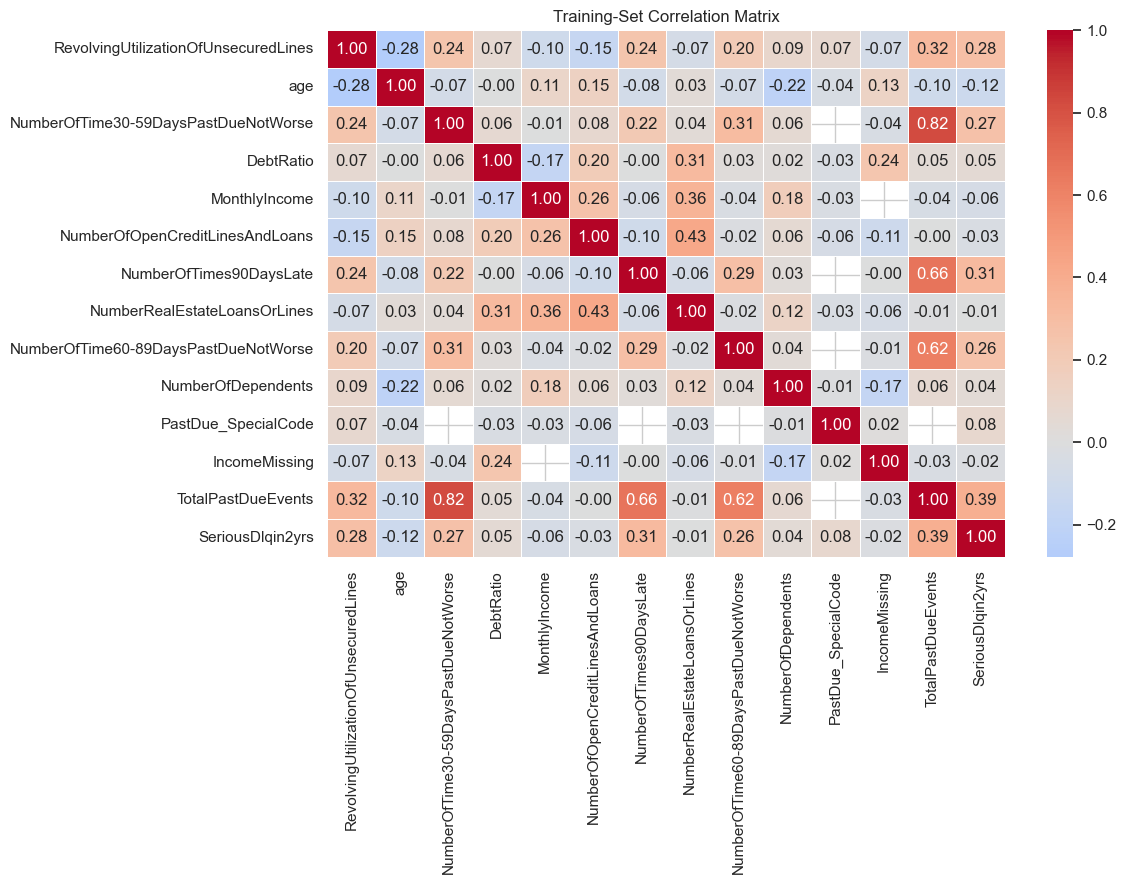

In [26]:
X_eda = Credit_df.drop(columns=[TARGET])
y_eda = Credit_df[TARGET]
X_train_eda, X_test_eda, y_train_eda, y_test_eda = train_test_split(
    X_eda, y_eda, test_size=0.2, random_state=SEED, stratify=y_eda
)

# Use training data only for percentile caps and correlation analysis.
heatmap_df = X_train_eda.copy()
utilization_cap = heatmap_df["RevolvingUtilizationOfUnsecuredLines"].quantile(0.99)
income_cap = heatmap_df["MonthlyIncome"].quantile(0.99)
heatmap_df["RevolvingUtilizationOfUnsecuredLines"] = heatmap_df[
    "RevolvingUtilizationOfUnsecuredLines"
].clip(upper=utilization_cap)
heatmap_df["MonthlyIncome"] = heatmap_df["MonthlyIncome"].clip(upper=income_cap)

heatmap_with_target = heatmap_df.copy()
heatmap_with_target[TARGET] = y_train_eda

plt.figure(figsize=(12, 9))
sns.heatmap(
    heatmap_with_target.corr(numeric_only=True),
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.5
)
plt.title("Training-Set Correlation Matrix")
plt.tight_layout()
plt.show()

In [27]:
correlations_with_target = (
    heatmap_with_target
    .corr(numeric_only=True)[TARGET]
    .sort_values(ascending=False)
)
print(correlations_with_target)

SeriousDlqin2yrs                        1.000000
TotalPastDueEvents                      0.389463
NumberOfTimes90DaysLate                 0.313255
RevolvingUtilizationOfUnsecuredLines    0.281931
NumberOfTime30-59DaysPastDueNotWorse    0.273689
NumberOfTime60-89DaysPastDueNotWorse    0.260759
PastDue_SpecialCode                     0.081991
DebtRatio                               0.047144
NumberOfDependents                      0.044923
NumberRealEstateLoansOrLines           -0.007739
IncomeMissing                          -0.020925
NumberOfOpenCreditLinesAndLoans        -0.030032
MonthlyIncome                          -0.061337
age                                    -0.115155
Name: SeriousDlqin2yrs, dtype: float64


As shown above, the variables most strongly correlated with `SeriousDlqin2yrs` are past-due delinquency counts and `RevolvingUtilizationOfUnsecuredLines`, confirming that recent credit repayment behavior and credit-line exhaustion are more directly predictive of default than demographic (age, dependents) and income-based predictors (income, real estate loans/lines, credit lines, etc.)

`age` is negatively correlated with revolving utilization ($\rho = -0.28$), positively correlated with the number of open credit lines ($r = 0.15$), and **negatively** correlated with `NumberOfDependents` ($r = -0.22$). This makes intuitive sense: older borrowers tend to have **fewer** financially dependent family members on their credit applications (e.g., empty-nest households as children reach adulthood), more open credit lines accumulated over a longer credit history, and lower credit utilization due to higher credit limits and less debt because they have had more time to pay off their loans.

## 5. Feature Engineering & Feature Subset Selection

We observed strong right skew in `MonthlyIncome`, `DebtRatio`, and `RevolvingUtilizationOfUnsecuredLines`. Crucially, many borrowers have legitimate `0` values for utilization or debt ratio (the lowest-risk group). Using `np.log(x.where(x > 0))` would turn `0` into `NaN` and median-impute those low-risk borrowers to a mid-risk value. Instead, we apply **`np.log1p(x)`** ($\log(1 + x)$), which maps `0` to `0.0` while compressing extreme right tails.

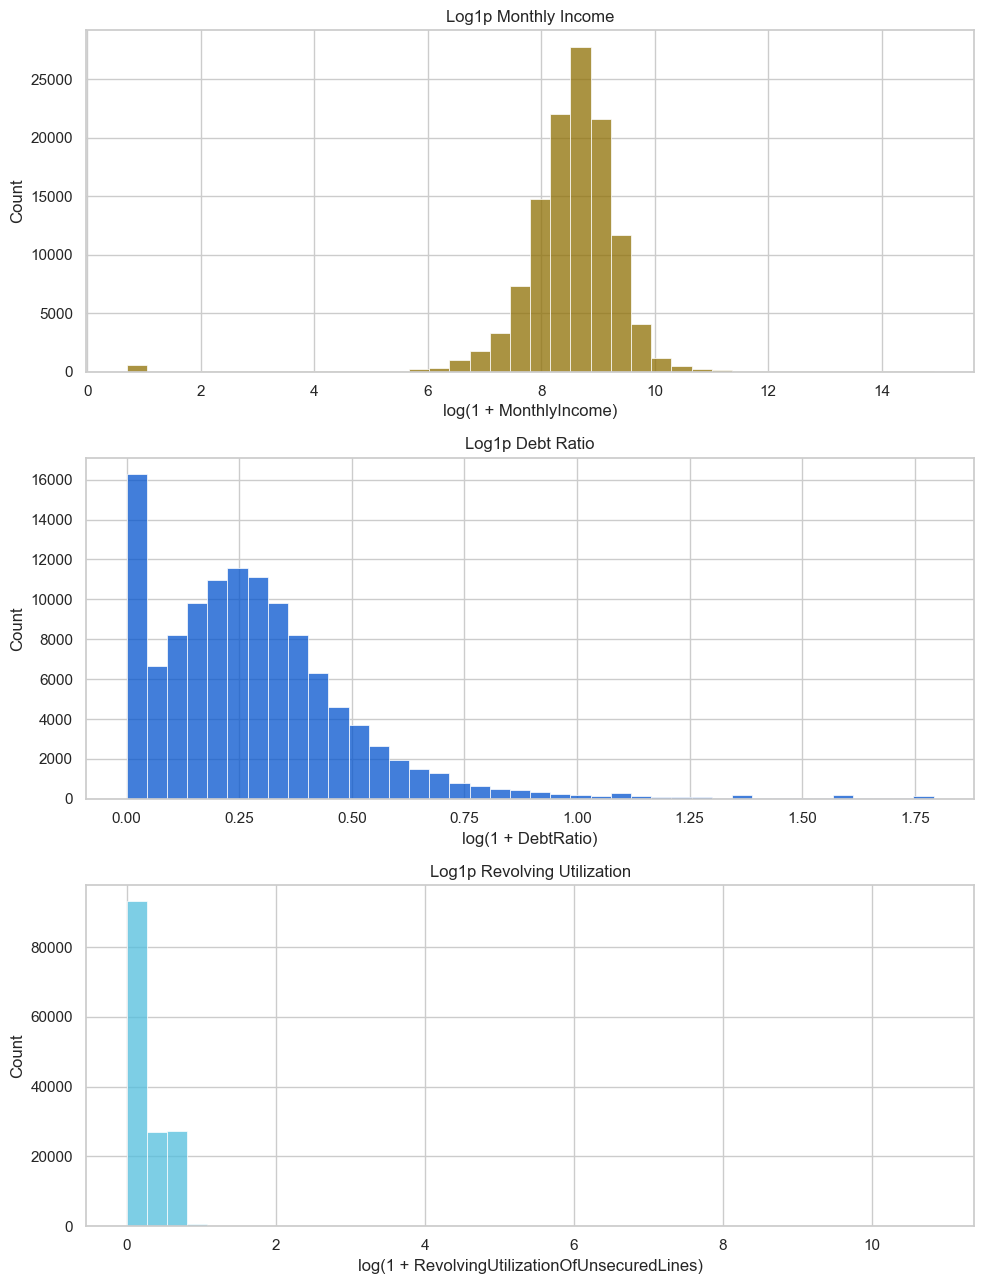

In [28]:
Credit_df["LogMonthlyIncome"] = np.log1p(
    Credit_df["MonthlyIncome"].clip(lower=0)
)
Credit_df["LogDebtRatio"] = np.log1p(
    Credit_df["DebtRatio"].clip(lower=0)
)
Credit_df["LogRevolvingUtilization"] = np.log1p(
    Credit_df["RevolvingUtilizationOfUnsecuredLines"].clip(lower=0)
)

fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 13))

sns.histplot(Credit_df["LogMonthlyIncome"].dropna(), bins=40, color = random_hex_color(), edgecolor="white", linewidth=0.5, ax=ax1)
ax1.set_title("Log1p Monthly Income")
ax1.set_xlabel("log(1 + MonthlyIncome)")
ax1.set_ylabel("Count")

sns.histplot(Credit_df["LogDebtRatio"].dropna(), bins=40, color= random_hex_color(), edgecolor="white", linewidth=0.5, ax=ax2)
ax2.set_title("Log1p Debt Ratio")
ax2.set_xlabel("log(1 + DebtRatio)")
ax2.set_ylabel("Count")

sns.histplot(Credit_df["LogRevolvingUtilization"].dropna(), bins=40, color= random_hex_color(), edgecolor="white", linewidth=0.5, ax=ax3)
ax3.set_title("Log1p Revolving Utilization")
ax3.set_xlabel("log(1 + RevolvingUtilizationOfUnsecuredLines)")
ax3.set_ylabel("Count")

plt.tight_layout()
plt.show()

Two applicants with similar monthly incomes can have very different cushions depending on family size. We engineer household income per person and apply `np.log1p`:
$$\text{Income2Members} = \dfrac{\text{MonthlyIncome}}{\text{NumberOfDependents} + 1}, \qquad \text{LogIncome2Members} = \log(1 + \text{Income2Members})$$

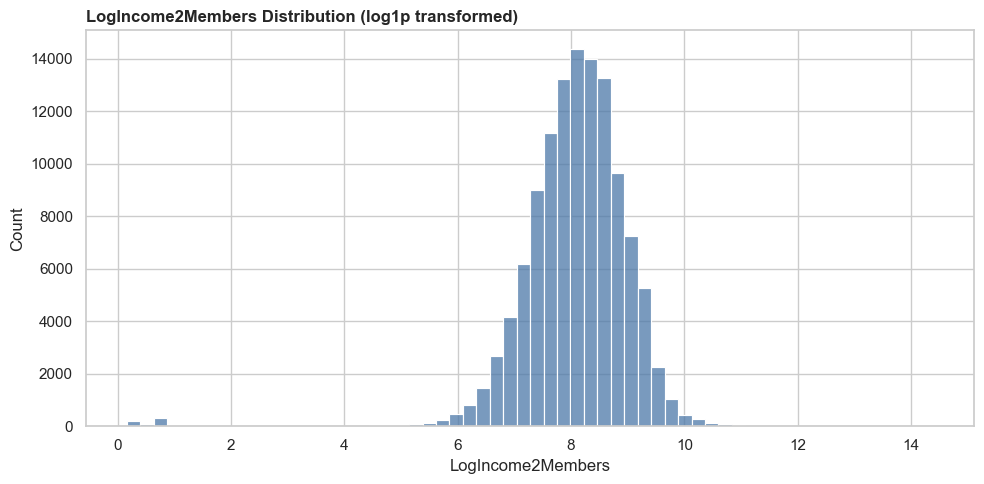

In [29]:
Credit_df["Income2Members"] = Credit_df["MonthlyIncome"] / (Credit_df["NumberOfDependents"].fillna(0) + 1)
Credit_df["LogIncome2Members"] = np.log1p(Credit_df["Income2Members"].clip(lower=0))

fig, ax = plt.subplots(1, 1, figsize=(10, 5))
sns.histplot(
    Credit_df["LogIncome2Members"].dropna(),
    bins=60,
    alpha=0.75,
    color="#4C78A8",
    ax=ax
)
ax.set_title("LogIncome2Members Distribution (log1p transformed)", loc="left", fontweight="bold")
plt.tight_layout()
plt.show()

### Choosing the Modeling Feature Subset (`SELECTED_FEATURES`)
We will keep the following features in our model evaluation:
1. **Keep `LogRevolvingUtilization`, `LogDebtRatio`, and `LogMonthlyIncome` (Drop raw `RevolvingUtilizationOfUnsecuredLines`, `DebtRatio`, and `MonthlyIncome`):** Retains the `log1p`-stabilized versions and drops the raw skewed duplicates. `LogIncome2Members` was explored in EDA but excluded from `SELECTED_FEATURES` to avoid collinearity with `LogMonthlyIncome` and `NumberOfDependents`.
2. **Keep `NumberOfTime30-59DaysPastDueNotWorse`, `NumberOfTime60-89DaysPastDueNotWorse`, `NumberOfTimes90DaysLate` (Drop `TotalPastDueEvents`):** `TotalPastDueEvents` is an exact linear sum of the three window columns and obscures severity differences.
3. **Keep single `PastDue_SpecialCode`:** Replaces the three identical special-code columns.
4. **Keep `IncomeMissing` (created once in Section 3):** Preserves the non-reporting signal.
5. **Keep `age`, `NumberOfOpenCreditLinesAndLoans`, `NumberRealEstateLoansOrLines`, `NumberOfDependents`:** Core credit capacity and lifecycle variables.

In [30]:


SELECTED_FEATURES = [
    "LogRevolvingUtilization",
    "age",
    "NumberOfTime30-59DaysPastDueNotWorse",
    "NumberOfTime60-89DaysPastDueNotWorse",
    "NumberOfTimes90DaysLate",
    "PastDue_SpecialCode",
    "LogDebtRatio",
    "LogMonthlyIncome",
    "IncomeMissing",
    "NumberOfOpenCreditLinesAndLoans",
    "NumberRealEstateLoansOrLines",
    "NumberOfDependents"
]

print(f"Selected {len(SELECTED_FEATURES)} modeling features:")
for i, feat in enumerate(SELECTED_FEATURES, 1):
    print(f"  {i:2d}. {feat}")

save_workspace_variables(["Credit_df", "SELECTED_FEATURES"])

Selected 12 modeling features:
   1. LogRevolvingUtilization
   2. age
   3. NumberOfTime30-59DaysPastDueNotWorse
   4. NumberOfTime60-89DaysPastDueNotWorse
   5. NumberOfTimes90DaysLate
   6. PastDue_SpecialCode
   7. LogDebtRatio
   8. LogMonthlyIncome
   9. IncomeMissing
  10. NumberOfOpenCreditLinesAndLoans
  11. NumberRealEstateLoansOrLines
  12. NumberOfDependents


## 6. Modeling
- **Calibration Integrity:** We do **not** use `class_weight="balanced"` in Logistic Regression or SVM, because artificial 50/50 reweighting distorts predicted probabilities away from the true ~6.68% base rate and breaks probability calibration in Section 7.
- **CV folds:** GBM and the logistic models are tuned with 5-fold CV; the EBM and the RBF SVM (15k subsample) use 3-fold CV for compute reasons, so their CV scores are not strictly like-for-like with the others.
- **Model Selection Protocol:** All hyperparameter tuning and model comparisons for selection are performed using **5-fold Stratified Cross-Validation ROC-AUC** on `X_train`. The held-out test set (`X_test`) is reserved strictly for final reporting.

In [31]:
X = Credit_df[SELECTED_FEATURES].copy()
y = Credit_df[TARGET].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

# Fit 99th-percentile outlier cap on X_train only, then apply to both splits.
log_util_cap = X_train["LogRevolvingUtilization"].quantile(0.99)
X_train["LogRevolvingUtilization"] = X_train["LogRevolvingUtilization"].clip(upper=log_util_cap)
X_test["LogRevolvingUtilization"] = X_test["LogRevolvingUtilization"].clip(upper=log_util_cap)

models = {
    "logreg_baseline": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("clf", LogisticRegression(penalty="l2", C=1.0, max_iter=2000, random_state=SEED)),
    ]),
    "ridge_logreg": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("clf", LogisticRegression(penalty="l2", max_iter=2000, random_state=SEED)),
    ]),
    "lasso_logreg": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("clf", LogisticRegression(penalty="l1", solver="saga", max_iter=2000, random_state=SEED)),
    ]),
    "elastic_net_logreg": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("sc", StandardScaler()),
        ("clf", LogisticRegression(penalty="elasticnet", solver="saga", l1_ratio=0.5, max_iter=2000, random_state=SEED)),
    ]),
    "gbm": Pipeline([
        ("imp", SimpleImputer(strategy="median")),
        ("clf", GradientBoostingClassifier(random_state=SEED)),
    ]),
}

In [32]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

# 1. Untuned baseline (fixed C=1.0, L2): fit on X_train and score with the same 5-fold CV used for tuning
baseline_logreg = models["logreg_baseline"].fit(X_train, y_train)
baseline_cv_auc = cross_val_score(
    models["logreg_baseline"], X_train, y_train, cv=cv, scoring="roc_auc", n_jobs=-1
).mean()

# 2. Tune models with Stratified 5-Fold Cross-Validation
param_grids = {
    "ridge_logreg": {"clf__C": [0.01, 0.1, 1.0, 10.0, 100.0]},
    "lasso_logreg": {"clf__C": [0.01, 0.1, 1.0, 10.0]},
    "elastic_net_logreg": {
        "clf__C": [0.01, 0.1, 1.0, 10.0],
        "clf__l1_ratio": [0.2, 0.5, 0.8],
    },
    "gbm": {
        "clf__n_estimators": [100, 200],
        "clf__learning_rate": [0.05, 0.1],
        "clf__max_depth": [3, 4],
    },
}

tuned_models = {"logreg_baseline": baseline_logreg}
cv_results = [{
    "model": "logreg_baseline",
    "best_cv_roc_auc": baseline_cv_auc,
    "best_params": "Fixed baseline (C=1.0, L2)",
}]

for name in tqdm(["ridge_logreg", "lasso_logreg", "elastic_net_logreg", "gbm"], desc="Tuning models"):
    search = GridSearchCV(
        estimator=models[name],
        param_grid=param_grids[name],
        scoring="roc_auc",
        cv=cv,
        n_jobs=-1,
        refit=True,
        verbose=0,
    )
    search.fit(X_train, y_train)
    tuned_models[name] = search.best_estimator_
    cv_results.append({
        "model": name,
        "best_cv_roc_auc": search.best_score_,
        "best_params": search.best_params_,
    })

cv_results = pd.DataFrame(cv_results).sort_values("best_cv_roc_auc", ascending=False)
print("5-Fold Stratified Cross-Validation Results (Model Selection Table):")
display(cv_results)

predicted_probabilities = {
    name: model.predict_proba(X_test)[:, 1]
    for name, model in tuned_models.items()
}

save_workspace_variables(["X_train", "X_test", "y_train", "y_test", "tuned_models", "cv_results", "predicted_probabilities"])


Tuning models:   0%|          | 0/4 [00:00<?, ?it/s]

5-Fold Stratified Cross-Validation Results (Model Selection Table):


,model,best_cv_roc_auc,best_params
4,gbm,0.863559,"{'clf__learning_rate': 0.05, 'clf__max_depth':..."
1,ridge_logreg,0.848584,{'clf__C': 0.01}
3,elastic_net_logreg,0.848580,"{'clf__C': 0.01, 'clf__l1_ratio': 0.2}"
2,lasso_logreg,0.848346,{'clf__C': 0.01}
0,logreg_baseline,0.848306,"Fixed baseline (C=1.0, L2)"


In [33]:
# Stratified subsample (15,000 rows) for RBF SVM so 3-fold CV remains practical with O(N^2) scaling.
# NOTE: the SVM and EBM use 3-fold CV (`additional_cv`); the logistic models and GBM use the 5-fold `cv` above.
additional_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
svm_idx, _ = train_test_split(
    np.arange(len(X_train)), train_size=15000, stratify=y_train, random_state=SEED
)
X_train_svm = X_train.iloc[svm_idx]
y_train_svm = y_train.iloc[svm_idx]

svm_rbf = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=SEED,
    )),
])

print("Fitting untuned RBF SVM (15k subsample)...")
svm_rbf.fit(X_train_svm, y_train_svm)
svm_untuned_scores = svm_rbf.predict_proba(X_test)[:, 1]
print(f"Untuned RBF SVM test ROC-AUC: {roc_auc_score(y_test, svm_untuned_scores):.4f}")
print("Tuning RBF SVM...")
svm_search = GridSearchCV(
    svm_rbf,
    {"classifier__C": [0.5, 1.0, 5.0], "classifier__gamma": ["scale", 0.05]},
    scoring="roc_auc",
    cv=additional_cv,
    n_jobs=-1,
    refit=True,
)
svm_search.fit(X_train_svm, y_train_svm)
tuned_svm = svm_search.best_estimator_
tuned_svm_scores = tuned_svm.predict_proba(X_test)[:, 1]
print(f"Tuned RBF SVM (15k subsample) test ROC-AUC: {roc_auc_score(y_test, tuned_svm_scores):.4f}")
print(f"Tuned RBF SVM best CV ROC-AUC: {svm_search.best_score_:.4f}")

Fitting untuned RBF SVM (15k subsample)...
Untuned RBF SVM test ROC-AUC: 0.6758
Tuning RBF SVM...
Tuned RBF SVM (15k subsample) test ROC-AUC: 0.6774
Tuned RBF SVM best CV ROC-AUC: 0.6796


In [34]:
# Explainable Boosting Machine (EBM)
tuned_ebm = None
ebm_best_cv_auc = np.nan
ebm_best_params = None

try:
    from interpret.glassbox import ExplainableBoostingClassifier
    ebm = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("clf", ExplainableBoostingClassifier(
            max_bins=128,
            outer_bags=4,
            inner_bags=0,
            random_state=SEED,
            n_jobs=-1,
        ))
    ])
    print("Fitting untuned EBM...")
    ebm.fit(X_train, y_train)
    ebm_untuned_scores = ebm.predict_proba(X_test)[:, 1]
    print(f"Untuned EBM test ROC-AUC: {roc_auc_score(y_test, ebm_untuned_scores):.4f}")
    print("Tuning EBM...")
    ebm_search = GridSearchCV(
        ebm,
        {
            "clf__interactions": [0, 5],
            "clf__max_rounds": [300],
            "clf__learning_rate": [0.02, 0.05],
        },
        scoring="roc_auc",
        cv=additional_cv,
        n_jobs=-1,
        refit=True,
    )
    ebm_search.fit(X_train, y_train)
    tuned_ebm = ebm_search.best_estimator_
    ebm_best_cv_auc = ebm_search.best_score_
    ebm_best_params = ebm_search.best_params_
    ebm_tuned_scores = tuned_ebm.predict_proba(X_test)[:, 1]
    print(f"Tuned EBM test ROC-AUC: {roc_auc_score(y_test, ebm_tuned_scores):.4f}")
    print(f"Tuned EBM best CV ROC-AUC: {ebm_best_cv_auc:.4f}")
except ImportError:
    print("interpret package not installed; skipping EBM.")

Fitting untuned EBM...
Untuned EBM test ROC-AUC: 0.8681
Tuning EBM...
Tuned EBM test ROC-AUC: 0.8666
Tuned EBM best CV ROC-AUC: 0.8618


In [35]:
# Packing up model scores for final comparison
model_scores = {
    **predicted_probabilities,
    "rbf_svm": tuned_svm.predict_proba(X_test)[:, 1],
}

extra_rows = [{
    "model": "rbf_svm",
    "best_cv_roc_auc": svm_search.best_score_,
    "best_params": svm_search.best_params_,
}]

if tuned_ebm is not None:
    model_scores["ebm"] = tuned_ebm.predict_proba(X_test)[:, 1]
    extra_rows.append({
        "model": "ebm",
        "best_cv_roc_auc": ebm_best_cv_auc,
        "best_params": ebm_best_params,
    })


additional_tuned_results = pd.DataFrame(extra_rows)
all_cv_results = pd.concat(
    [cv_results[["model", "best_cv_roc_auc", "best_params"]], additional_tuned_results],
    ignore_index=True
)

all_cv_results["test_roc_auc"] = all_cv_results["model"].map(
    lambda name: roc_auc_score(y_test, model_scores[name])
)
all_cv_results["average_precision"] = all_cv_results["model"].map(
    lambda name: average_precision_score(y_test, model_scores[name])
)
all_cv_results["brier_score"] = all_cv_results["model"].map(
    lambda name: brier_score_loss(y_test, model_scores[name])
)

# Sort by Cross-Validation ROC-AUC to select the champion model without test-set leakage
tuned_results = all_cv_results.sort_values("best_cv_roc_auc", ascending=False).reset_index(drop=True)
champion_model_name = tuned_results.iloc[0]["model"]
print(f"Champion Model selected by Cross-Validation ROC-AUC: {champion_model_name}")
display(tuned_results)

save_workspace_variables(["model_scores", "tuned_results", "champion_model_name"])

Champion Model selected by Cross-Validation ROC-AUC: gbm


,model,best_cv_roc_auc,best_params,test_roc_auc,average_precision,brier_score
0,gbm,0.863559,"{'clf__learning_rate': 0.05, 'clf__max_depth':...",0.867697,0.407532,0.048767
1,ebm,0.861800,"{'clf__interactions': 5, 'clf__learning_rate':...",0.866645,0.404883,0.049023
2,ridge_logreg,0.848584,{'clf__C': 0.01},0.856458,0.395375,0.050202
3,elastic_net_logreg,0.848580,"{'clf__C': 0.01, 'clf__l1_ratio': 0.2}",0.856453,0.395348,0.050202
4,lasso_logreg,0.848346,{'clf__C': 0.01},0.856314,0.395445,0.050200
5,logreg_baseline,0.848306,"Fixed baseline (C=1.0, L2)",0.856261,0.395006,0.050206
6,rbf_svm,0.679628,"{'classifier__C': 0.5, 'classifier__gamma': 's...",0.677431,0.297010,0.057447


In [36]:
# Full best-parameter dicts (the table above truncates long values)
for _, row in tuned_results.iterrows():
    print(f"{row['model']:>20s}  {row['best_params']}")


                 gbm  {'clf__learning_rate': 0.05, 'clf__max_depth': 4, 'clf__n_estimators': 200}
                 ebm  {'clf__interactions': 5, 'clf__learning_rate': 0.02, 'clf__max_rounds': 300}
        ridge_logreg  {'clf__C': 0.01}
  elastic_net_logreg  {'clf__C': 0.01, 'clf__l1_ratio': 0.2}
        lasso_logreg  {'clf__C': 0.01}
     logreg_baseline  Fixed baseline (C=1.0, L2)
             rbf_svm  {'classifier__C': 0.5, 'classifier__gamma': 'scale'}


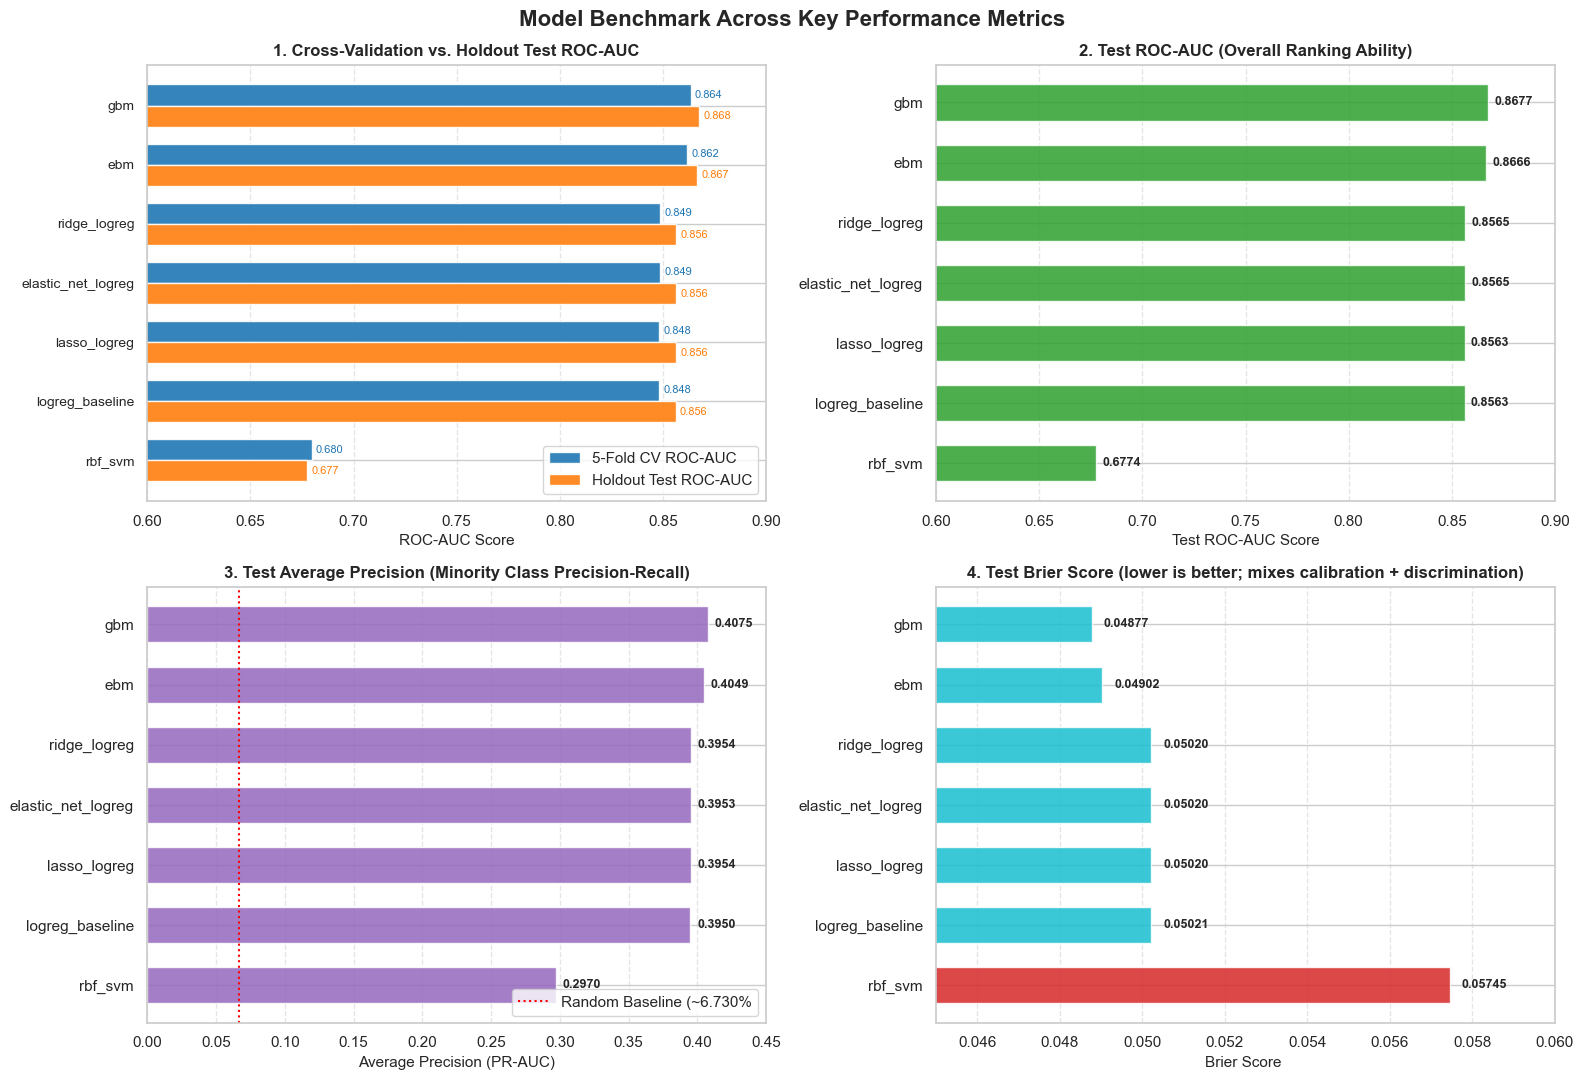

In [45]:


# Ensure DataFrame is sorted by CV ROC-AUC ascending so the top models appear at the top
plot_df = tuned_results.sort_values("best_cv_roc_auc", ascending=True).reset_index(drop=True)

fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Model Benchmark Across Key Performance Metrics", fontsize=16, fontweight="bold", y=0.98)

# CV vs. Hold out Test ROC-AUC
y_pos = np.arange(len(plot_df))
bar_height = 0.36

axes[0, 0].barh(y_pos + bar_height/2, plot_df["best_cv_roc_auc"], height=bar_height, 
                color="#1f77b4", label="5-Fold CV ROC-AUC", alpha=0.9)
axes[0, 0].barh(y_pos - bar_height/2, plot_df["test_roc_auc"], height=bar_height, 
                color="#ff7f0e", label="Holdout Test ROC-AUC", alpha=0.9)
axes[0, 0].set_yticks(y_pos)
axes[0, 0].set_yticklabels(plot_df["model"], fontsize=10, fontweight="medium")
axes[0, 0].set_xlim(0.60, 0.90)
axes[0, 0].set_xlabel("ROC-AUC Score", fontsize=11)
axes[0, 0].set_title("1. Cross-Validation vs. Holdout Test ROC-AUC", fontweight="bold", fontsize=12)
axes[0, 0].legend(loc="lower right", frameon=True)
axes[0, 0].grid(axis="x", linestyle="--", alpha=0.5)

for i in y_pos:
    axes[0, 0].text(plot_df["best_cv_roc_auc"][i] + 0.002, i + bar_height/2, 
                    f"{plot_df['best_cv_roc_auc'][i]:.3f}", va="center", fontsize=8, color="#1f77b4")
    axes[0, 0].text(plot_df["test_roc_auc"][i] + 0.002, i - bar_height/2, 
                    f"{plot_df['test_roc_auc'][i]:.3f}", va="center", fontsize=8, color="#ff7f0e")

# Test ROC-AUC 
bars2 = axes[0, 1].barh(plot_df["model"], plot_df["test_roc_auc"], color="#2ca02c", alpha=0.85, height=0.6)
axes[0, 1].set_xlim(0.60, 0.90)
axes[0, 1].set_xlabel("Test ROC-AUC Score", fontsize=11)
axes[0, 1].set_title("2. Test ROC-AUC (Overall Ranking Ability)", fontweight="bold", fontsize=12)
axes[0, 1].grid(axis="x", linestyle="--", alpha=0.5)

for bar in bars2:
    w = bar.get_width()
    axes[0, 1].text(w + 0.003, bar.get_y() + bar.get_height()/2, 
                    f"{w:.4f}", va="center", fontsize=9, fontweight="bold")

# Test PR-AUC 
bars3 = axes[1, 0].barh(plot_df["model"], plot_df["average_precision"], color="#9467bd", alpha=0.85, height=0.6)
axes[1, 0].axvline(0.0668, color="red", linestyle=":", linewidth=1.5, label=f"Random Baseline (~{y_test.mean()*100:.3f}%")
axes[1, 0].set_xlim(0.0, 0.45)
axes[1, 0].set_xlabel("Average Precision (PR-AUC)", fontsize=11)
axes[1, 0].set_title("3. Test Average Precision (Minority Class Precision-Recall)", fontweight="bold", fontsize=12)
axes[1, 0].legend(loc="lower right", frameon=True)
axes[1, 0].grid(axis="x", linestyle="--", alpha=0.5)

for bar in bars3:
    w = bar.get_width()
    axes[1, 0].text(w + 0.005, bar.get_y() + bar.get_height()/2, 
                    f"{w:.4f}", va="center", fontsize=9, fontweight="bold")

# Test brier
colors_brier = ["#d62728" if m == "rbf_svm" else "#17becf" for m in plot_df["model"]]
bars4 = axes[1, 1].barh(plot_df["model"], plot_df["brier_score"], color=colors_brier, alpha=0.85, height=0.6)
axes[1, 1].set_xlim(0.045, 0.060)
axes[1, 1].set_xlabel("Brier Score ", fontsize=11)
axes[1, 1].set_title("4. Test Brier Score (lower is better; mixes calibration + discrimination)", fontweight="bold", fontsize=12)
axes[1, 1].grid(axis="x", linestyle="--", alpha=0.5)

for bar in bars4:
    w = bar.get_width()
    axes[1, 1].text(w + 0.0003, bar.get_y() + bar.get_height()/2, 
                    f"{w:.5f}", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()


- **Discussion:** Choosing strictly by Cross-Validation ROC-AUC on `X_train` (keeping `X_test` untouched for final reporting), `gbm` (~0.864) and `ebm` (~0.862) lead the regularized logistic models (~0.848-0.849), consistent with non-linear effects in revolving utilization and delinquency counts (not tested directly here).
- **Caveats:** (1) GBM and the logistic models use 5-fold CV while the EBM and SVM use 3-fold (SVM on a 15k subsample), so CV scores are not strictly like-for-like; (2) the GBM-vs-EBM gaps (0.0018 CV, 0.0010 test ROC-AUC) are small, so treat them as roughly tied, with `gbm` selected by the stated rule; (3) the RBF SVM (~0.68 ROC-AUC) falls far below even the linear baseline and has an erratic reliability curve. This is likely a limitation of the 15k subsample and outlier-heavy count features under an RBF kernel (untested), so treat it as a weak benchmark rather than evidence about kernel methods.


## 7. Evaluation
- **ROC-AUC and Precision-Recall curves** on the held-out test set (`X_test`)
- **Probability Calibration Check** (reliability diagram & Brier score to verify predicted probabilities can be used directly as PDs)
- **Feature Importance & Coefficient Sanity Check** (verifying sign and magnitude align with credit risk domain knowledge)
- **Confusion Matrix** at the business-optimal probability threshold

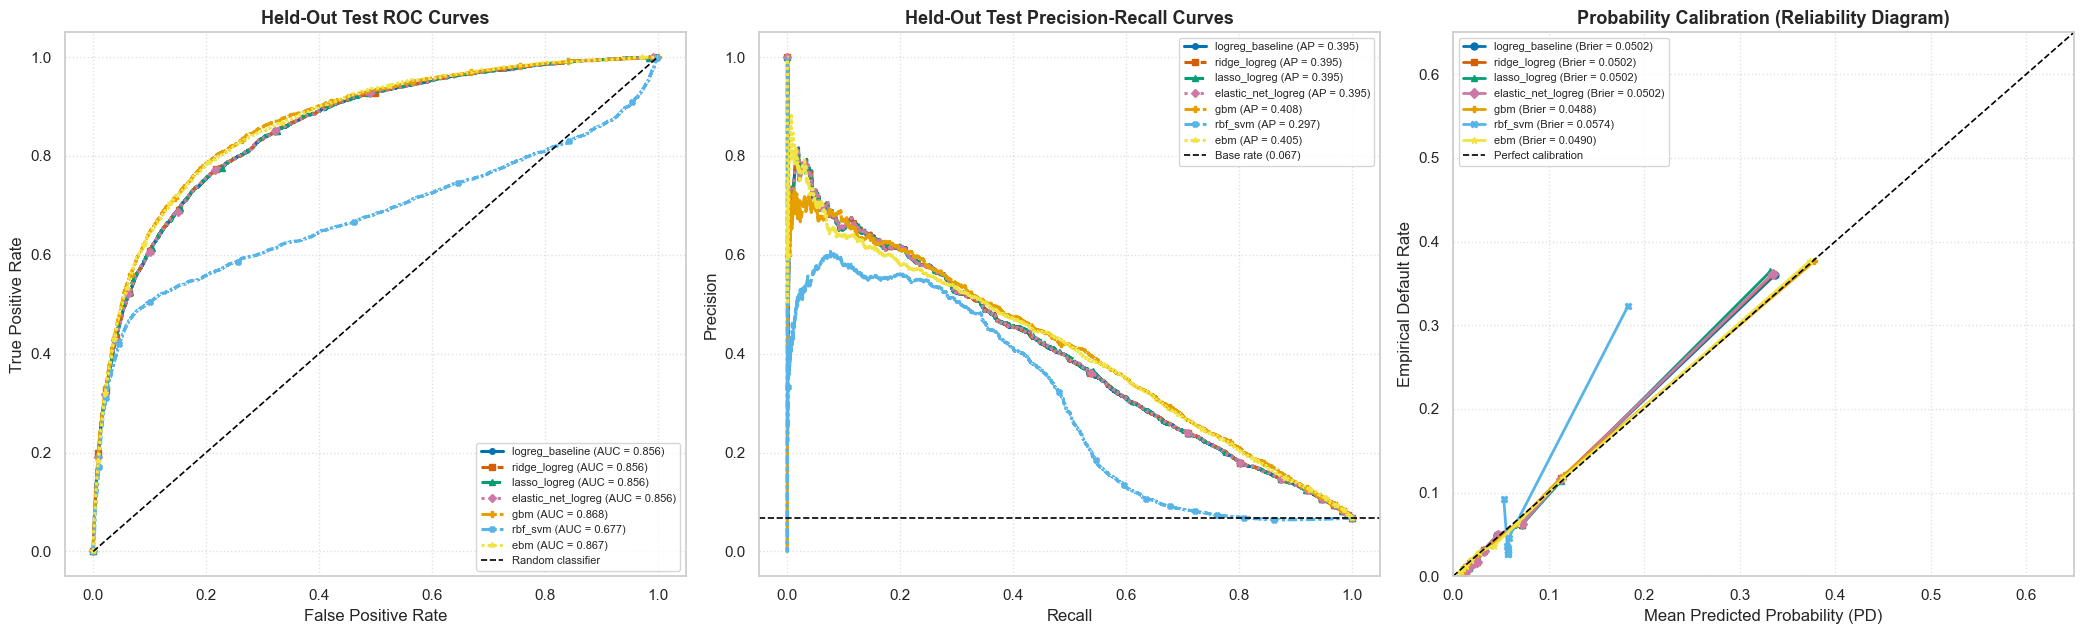

In [38]:
colors = ["#0072B2", "#D55E00", "#009E73", "#CC79A7", "#E69F00", "#56B4E9", "#F0E442", "#000000"]
line_styles = ["-", "--", "-.", ":", (0, (5, 1)), (0, (3, 1, 1, 1)), (0, (1, 1)), (0, (5, 2, 1, 2))]
markers = ["o", "s", "^", "D", "P", "X", "*", "v"]

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))

# 1. ROC Curves
for (model_name, scores), color, line_style, marker in zip(model_scores.items(), colors, line_styles, markers):
    fpr, tpr, _ = roc_curve(y_test, scores)
    auc_val = roc_auc_score(y_test, scores)
    axes[0].plot(
        fpr, tpr, color=color, linestyle=line_style, linewidth=2.2,
        marker=marker, markersize=4, markevery=max(1, len(fpr) // 10),
        label=f"{model_name} (AUC = {auc_val:.3f})"
    )
axes[0].plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1.2, label="Random classifier")
axes[0].set_title("Held-Out Test ROC Curves", fontsize=13, fontweight="bold")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend(loc="lower right", fontsize=8)
axes[0].grid(True, linestyle=":", alpha=0.6)

# 2. Precision-Recall Curves
for (model_name, scores), color, line_style, marker in zip(model_scores.items(), colors, line_styles, markers):
    precision, recall, _ = precision_recall_curve(y_test, scores)
    ap_val = average_precision_score(y_test, scores)
    axes[1].plot(
        recall, precision, color=color, linestyle=line_style, linewidth=2.2,
        marker=marker, markersize=4, markevery=max(1, len(recall) // 10),
        label=f"{model_name} (AP = {ap_val:.3f})"
    )
axes[1].axhline(y_test.mean(), color="black", linestyle="--", linewidth=1.2, label=f"Base rate ({y_test.mean():.3f})")
axes[1].set_title("Held-Out Test Precision-Recall Curves", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend(loc="upper right", fontsize=8)
axes[1].grid(True, linestyle=":", alpha=0.6)

# 3. Calibration / Reliability Curves
for (model_name, scores), color, marker in zip(model_scores.items(), colors, markers):
    prob_true, prob_pred = calibration_curve(y_test, np.clip(scores, 0, 1), n_bins=10, strategy="quantile")
    brier = brier_score_loss(y_test, np.clip(scores, 0, 1))
    axes[2].plot(
        prob_pred, prob_true, color=color, linewidth=2.0, marker=marker, markersize=5,
        label=f"{model_name} (Brier = {brier:.4f})"
    )
axes[2].plot([0, 1], [0, 1], color="black", linestyle="--", linewidth=1.2, label="Perfect calibration")
axes[2].set_title("Probability Calibration (Reliability Diagram)", fontsize=13, fontweight="bold")
axes[2].set_xlabel("Mean Predicted Probability (PD)")
axes[2].set_ylabel("Empirical Default Rate")
axes[2].set_xlim(0, 0.65)
axes[2].set_ylim(0, 0.65)
axes[2].legend(loc="upper left", fontsize=8)
axes[2].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
plt.show()

**Reading the plots:** `gbm`, `ebm`, and the logistic models track the 45-degree line closely up to PD ~0.35, so their scores can be used as PDs; the logistic models slightly under-predict risk in the top decile. The RBF SVM's reliability curve is erratic, another sign it is a weak benchmark here. Brier score combines calibration and discrimination, so the reliability diagram is the direct calibration check.


,Feature,GBM_Importance,Ridge_LogOdds_Coef
4,NumberOfTimes90DaysLate,0.499307,0.326006
0,LogRevolvingUtilization,0.186124,0.722979
2,NumberOfTime30-59DaysPastDueNotWorse,0.100453,0.300968
3,NumberOfTime60-89DaysPastDueNotWorse,0.083320,0.185346
6,LogDebtRatio,0.032845,0.098814
5,PastDue_SpecialCode,0.024232,0.098475
1,age,0.022686,-0.258149
7,LogMonthlyIncome,0.019400,-0.057208
9,NumberOfOpenCreditLinesAndLoans,0.016844,0.101977
10,NumberRealEstateLoansOrLines,0.010708,0.057919


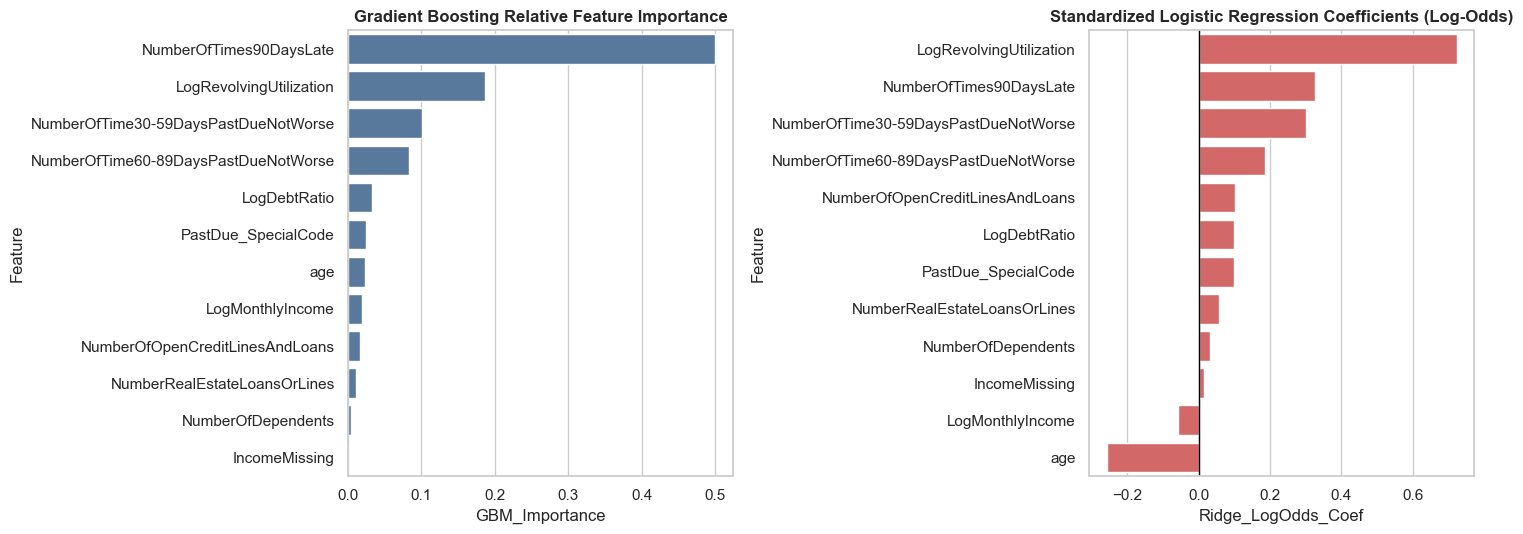

In [39]:
# Feature Importance (GBM) & Standardized Coefficients (Ridge Logistic Regression) Sanity Check
gbm_clf = tuned_models["gbm"].named_steps["clf"]
ridge_clf = tuned_models["ridge_logreg"].named_steps["clf"]

importance_df = pd.DataFrame({
    "Feature": SELECTED_FEATURES,
    "GBM_Importance": gbm_clf.feature_importances_,
    "Ridge_LogOdds_Coef": ridge_clf.coef_[0]
}).sort_values("GBM_Importance", ascending=False)

display(importance_df)

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.barplot(data=importance_df, x="GBM_Importance", y="Feature", color="#4C78A8", ax=axes[0])
axes[0].set_title("Gradient Boosting Relative Feature Importance", fontweight="bold")

coef_sorted = importance_df.sort_values("Ridge_LogOdds_Coef", ascending=False)
sns.barplot(data=coef_sorted, x="Ridge_LogOdds_Coef", y="Feature", color="#E45756", ax=axes[1])
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_title("Standardized Logistic Regression Coefficients (Log-Odds)", fontweight="bold")

plt.tight_layout()
plt.show()

**Sanity check:** signs match domain expectations for utilization and delinquency counts (positive) and for age and income (negative). `NumberOfOpenCreditLinesAndLoans` (+0.10) and `NumberRealEstateLoansOrLines` (+0.06) have positive Ridge coefficients even though their marginal correlations with default are slightly negative (-0.03 and -0.01); conditional on the other features (e.g. debt ratio and income), they pick up leverage. Ridge with `C=0.01` also shrinks every coefficient, and GBM impurity importance (dominated by `NumberOfTimes90DaysLate`) is biased toward high-cardinality splits, so read both as directional.


## 8. Financial / Business Impact
- **Loan Economics Assumptions (using reasonable values to have some concrete numbers to mess with):**
  - **Good Loan (`SeriousDlqin2yrs = 0`, True Negative):** Generates **+$1,200** net interest and fee profit over the 2-year horizon.
  - **Defaulted Loan (`SeriousDlqin2yrs = 1`, False Negative - approved defaulter):** Incurs **-$10,000** net Loss Given Default (LGD * EAD).
  - **Declined Application (`Predicted = 1`, True Positive or False Positive):** **$0** direct cash flow ($0 loss on avoided default; foregone interest on declined good borrower is captured by not earning +$1,200).
- **Theoretical Break-Even Probability Threshold ($p^*$):**  
Let $p = P(Default)$
Let $E[\Pi] =$ expected profit of approving a loan:   

$E[\Pi|Approve]= P(\text{Non-default})*(\text{Profit from loan}) + P(\text{default})*(\text{Loss from defaulted loan})$  
$E[\Pi|Approve]= (1-p) \cdot \ 1,200 + (p) \cdot -10,000$  
Optimal threshold $p^*$ occurs when $E[\Pi|Approve] = 0$  
Let $E[\Pi|Approve] = 0$  
$0 = (1-p^*) \cdot \ 1,200 + (p^*) \cdot -10,000$  
$\implies$  

$p^* = \frac{\text{Profit}_{\text{Good}}}{\text{Profit}_{\text{Good}} + \text{Loss}_{\text{Default}}} = \frac{1200}{1200 + 10000} \approx 0.1071 \; (10.7\%)$
- **Policy choice:** the headline policy is the theoretical cutoff, which does not use test labels. The empirical profit sweep below is a sensitivity check only (its optimum is chosen on the test set, so it is optimistic).


No-Model Baseline (Approve 100%): Total Profit = $13,242,400 ($446.26 / applicant) | Bad Rate = 6.73%
GBM theoretical cutoff (PD < 0.1071): Total Profit = $22,844,000 ($769.83 / applicant)
  -> Approval Rate: 84.8% | Approved Portfolio Bad Rate: 2.61%
  -> Net Value Added over Approve-All Baseline (Test Set): +$9,601,600
[Sensitivity] Empirical grid optimum (test-selected): Total Profit = $22,853,200 ($770.14 / applicant) | Approval Rate: 84.0% | Bad Rate: 2.52%
  -> +$9,610,800 vs. baseline; +$9,200 vs. the theoretical cutoff


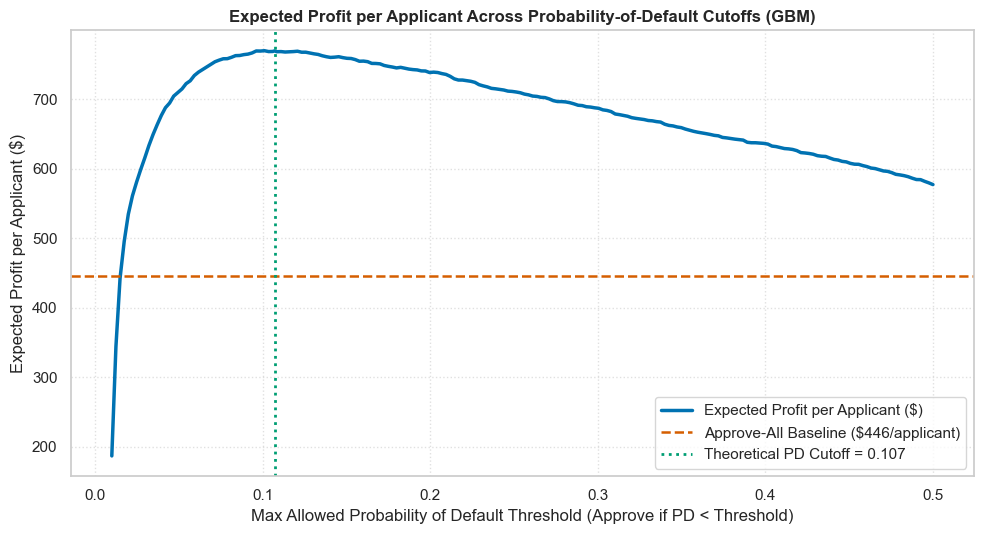


Confusion Matrix at Theoretical Business Threshold (PD >= 0.107 -> Decline):


,Predicted Approve (0),Predicted Decline (1)
Actual Good (0),24520,3157
Actual Default (1),658,1339


              precision    recall  f1-score   support

 Approve (0)       0.97      0.89      0.93     27677
 Decline (1)       0.30      0.67      0.41      1997

    accuracy                           0.87     29674
   macro avg       0.64      0.78      0.67     29674
weighted avg       0.93      0.87      0.89     29674



In [40]:
PROFIT_GOOD_LOAN = 1200.0
LOSS_DEFAULT_LOAN = -10000.0

champ_probs = model_scores["gbm"]
thresholds = np.linspace(0.01, 0.50, 200)
theoretical_threshold = PROFIT_GOOD_LOAN / (PROFIT_GOOD_LOAN - LOSS_DEFAULT_LOAN)
thresholds = np.sort(np.append(thresholds, theoretical_threshold))

# Approve loan if predicted PD < threshold; decline if predicted PD >= threshold
records = []
for t in thresholds:
    approved_mask = champ_probs < t
    n_approved = approved_mask.sum()
    good_approved = ((y_test == 0) & approved_mask).sum()
    bad_approved = ((y_test == 1) & approved_mask).sum()
    total_profit = good_approved * PROFIT_GOOD_LOAN + bad_approved * LOSS_DEFAULT_LOAN
    records.append({
        "threshold": t,
        "total_profit": total_profit,
        "profit_per_applicant": total_profit / len(y_test),
        "approval_rate_pct": (n_approved / len(y_test)) * 100,
        "approved_bad_rate_pct": (bad_approved / n_approved * 100) if n_approved > 0 else 0.0,
    })

profit_curve_df = pd.DataFrame(records)

# Headline policy: theoretical break-even cutoff (does not use test labels to choose the threshold)
theory_row = profit_curve_df.loc[np.isclose(profit_curve_df["threshold"], theoretical_threshold)].iloc[0]
# Sensitivity check only: empirical profit-maximizing cutoff on the grid (chosen with test labels, so optimistic)
best_row = profit_curve_df.loc[profit_curve_df["total_profit"].idxmax()]

# Baseline: Approve everyone (threshold = 1.0)
all_good = (y_test == 0).sum()
all_bad = (y_test == 1).sum()
baseline_total_profit = all_good * PROFIT_GOOD_LOAN + all_bad * LOSS_DEFAULT_LOAN
baseline_profit_per_app = baseline_total_profit / len(y_test)

print(f"No-Model Baseline (Approve 100%): Total Profit = ${baseline_total_profit:,.0f} (${baseline_profit_per_app:,.2f} / applicant) | Bad Rate = {y_test.mean()*100:.2f}%")
print(f"GBM theoretical cutoff (PD < {theoretical_threshold:.4f}): Total Profit = ${theory_row['total_profit']:,.0f} (${theory_row['profit_per_applicant']:,.2f} / applicant)")
print(f"  -> Approval Rate: {theory_row['approval_rate_pct']:.1f}% | Approved Portfolio Bad Rate: {theory_row['approved_bad_rate_pct']:.2f}%")
print(f"  -> Net Value Added over Approve-All Baseline (Test Set): +${theory_row['total_profit'] - baseline_total_profit:,.0f}")
print(f"[Sensitivity] Empirical grid optimum (test-selected): Total Profit = ${best_row['total_profit']:,.0f} (${best_row['profit_per_applicant']:,.2f} / applicant) | Approval Rate: {best_row['approval_rate_pct']:.1f}% | Bad Rate: {best_row['approved_bad_rate_pct']:.2f}%")
print(f"  -> +${best_row['total_profit'] - baseline_total_profit:,.0f} vs. baseline; +${best_row['total_profit'] - theory_row['total_profit']:,.0f} vs. the theoretical cutoff")

fig, ax1 = plt.subplots(figsize=(10, 5.5))
ax1.plot(profit_curve_df["threshold"], profit_curve_df["profit_per_applicant"], color="#0072B2", linewidth=2.5, label="Expected Profit per Applicant ($)")
ax1.axhline(baseline_profit_per_app, color="#D55E00", linestyle="--", linewidth=1.8, label=f"Approve-All Baseline (${baseline_profit_per_app:,.0f}/applicant)")
ax1.axvline(theoretical_threshold, color="#009E73", linestyle=":", linewidth=2.0, label=f"Theoretical PD Cutoff = {theoretical_threshold:.3f}")
ax1.set_title("Expected Profit per Applicant Across Probability-of-Default Cutoffs (GBM)", fontweight="bold")
ax1.set_xlabel("Max Allowed Probability of Default Threshold (Approve if PD < Threshold)")
ax1.set_ylabel("Expected Profit per Applicant ($)")
ax1.legend(loc="lower right")
ax1.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# Confusion Matrix at Optimal Business Threshold
y_pred_opt = (champ_probs >= theoretical_threshold).astype(int)
cm = confusion_matrix(y_test, y_pred_opt)
cm_df = pd.DataFrame(
    cm,
    index=["Actual Good (0)", "Actual Default (1)"],
    columns=["Predicted Approve (0)", "Predicted Decline (1)"]
)
print(f"\nConfusion Matrix at Theoretical Business Threshold (PD >= {theoretical_threshold:.3f} -> Decline):")
display(cm_df)
print(classification_report(y_test, y_pred_opt, target_names=["Approve (0)", "Decline (1)"]))

save_workspace_variables(["profit_curve_df", "theoretical_threshold", "cm_df"])

Using the values in this confusion matrix (theoretical 10.71% cutoff), we can calculate the net profit gain ($\Delta\text{Profit}$):  
$\text{Model Profit} = 24,520 \times 1,200 + 658 \times (-10,000) = 22,844,000$  
$\text{Baseline (Approve-All) Profit} = 27,677 \times 1,200 + 1,997 \times (-10,000) = 13,242,400$  

$\Delta \text{Profit} = 22,844,000 - 13,242,400 = 9,601,600 \approx$ $9.60\text{ million}$ on the test sample.

The empirical grid optimum is chosen using test labels (so it is optimistic) and earns $22,853,200 (+$9,610,800 vs. baseline), only $9,200 (~0.04%) more than the theoretical cutoff. We therefore report the theoretical cutoff as the headline policy.


In [41]:
PROFIT_PER_GOOD_APPROVAL = 1_200
LOSS_PER_BAD_APPROVAL = -10_000


approved_good = int(cm_df.loc["Actual Good (0)", "Predicted Approve (0)"])
approved_bad = int(cm_df.loc["Actual Default (1)", "Predicted Approve (0)"])

optimal_model_profit = (
    approved_good * PROFIT_PER_GOOD_APPROVAL
    + approved_bad * LOSS_PER_BAD_APPROVAL
)

# Approve-all baseline: every good loan earns $1,200 and every bad loan loses $10,000.
baseline_good = int((y_test == 0).sum())
baseline_bad = int((y_test == 1).sum())
baseline_model_profit = (
    baseline_good * PROFIT_PER_GOOD_APPROVAL
    + baseline_bad * LOSS_PER_BAD_APPROVAL
)

delta_profit = optimal_model_profit - baseline_model_profit

print(f"Approved good loans (optimal model): {approved_good:,}")
print(f"Approved bad loans (optimal model): {approved_bad:,}")
print(f"Optimal model profit: ${optimal_model_profit:,.0f}")
print(f"Baseline good loans approved: {baseline_good:,}")
print(f"Baseline bad loans approved: {baseline_bad:,}")
print(f"Baseline model profit: ${baseline_model_profit:,.0f}")
print(f"Delta profit: ${delta_profit:,.0f} ({delta_profit / 1_000_000:.2f} million)")

Approved good loans (optimal model): 24,520
Approved bad loans (optimal model): 658
Optimal model profit: $22,844,000
Baseline good loans approved: 27,677
Baseline bad loans approved: 1,997
Baseline model profit: $13,242,400
Delta profit: $9,601,600 (9.60 million)


## 9. Conclusions & Next Steps

- **Key Drivers of Default:**
  1. **Historical Delinquency Severity & Frequency:** Prior 90+ day, 60 - 89 day, and 30-59 day past-due events (along with the consolidated `PastDue_SpecialCode` flag) are the strongest predictors of future serious delinquency, with a single 90+ day late event increasing default risk by ~29 percentage points.
  2. **Revolving Credit Exhaustion (`LogRevolvingUtilization`):** Borrowers at 75-100% utilization of their unsecured revolving credit limits default at ~18.6% (about 2.8x the 6.73% base rate), and those over 100% default at ~37% (about 5.5x).
  3. **Lifecycle & Debt Servicing Capacity (`age`, `LogDebtRatio`, `LogMonthlyIncome`):** Younger borrowers with higher debt-to-income ratios and lower monthly incomes exhibit significantly elevated default risk.
- **Model Performance & Recommended Policy:**
  - **Gradient Boosting (`gbm`)** achieved the strongest 5-fold CV ROC-AUC (0.8636) and held-out test ROC-AUC (0.8677) with a Brier score of ~0.0488, about a 22% reduction vs. a naive base-rate forecast (~0.0628). `ebm` is statistically close (CV 0.8618, test 0.8666).
  - The theoretical cutoff is **PD $\ge 10.71\%$** (decline). On the 29,674-applicant test sample it approves **84.8%** of applicants (25,178), reduces the approved portfolio default rate from **6.73% to 2.61%**, and increases net lending profit by **$9.60M** (+$323.57 per applicant) vs. approve-all. A test-selected grid optimum adds only $9,200 more, so we keep the theoretical cutoff.
- **Limitations:**
  - **Selection Bias (Approved-Only Sample):** Training data only contains borrowers who were historically granted credit, rejected applicants were unobserved.
  - **Lack of Temporal & Macroeconomic Context:** The dataset is a static cross-section with no origination dates, interest rate environments, or unemployment indicators.
  - **Fair Lending Considerations:** Under ECOA / Regulation B, `age` cannot be used to penalize elderly applicants. any production scorecard must take this into account
- **Evaluation Caveats:** EBM and the SVM were tuned with 3-fold CV (SVM on a 15k subsample); all results come from a single stratified holdout split; the profit sweep's optimum is chosen on the test set and is a sensitivity check only.
- **Next Steps:**
  - Enforce **monotonicity constraints** (e.g., in LightGBM / XGBoost / EBM) so predicted default risk is guaranteed to increase monotonically with utilization and past-due counts for adverse-action reason codes.
    - Under fair lending laws, banks must defend their choice whenever they reject someone. A model like this that does not increase monotonically with utilization and past due counts would raise serious questions. For example, the predicted risk could be lower for someone with slightly more past due events. Enforcing monotonicity would make the model more defensible.
  - Perform **Out-of-Time (OOT) validation** across loan origination vintages and incorporate bureau trended data (6-to-24 month utilization velocity). This data set offered a static snapshot of someone's utilization, which can lead to inaccuracies. For example, if two people have similar utilizations, but one has been increasing utilization over time (burning through credit) and one has been decreasing (paying off debts), they will be treated similarly, even though the person on an upward trend is more likely to default.